# CASMI26: fingerprint MLP

**Strand:** fingerprint MLP (Thomas F). **Feeds:** `03-Neural-Models` (MLP half), the MLP rows of
`04-Scaling` and, through `results/mlp/`, `05-Results`. **Reads:** the hand-off files written by
`01-data-and-validation`, and Michael's shared 5% split `stage_1_5pct` (section 13).

An MLP reads a spectrum and predicts which of 2,048 substructure bits (a Morgan fingerprint) its
molecule has. Candidate molecules of the right mass are then ranked by how well their fingerprints
match the prediction. This is the route taken by CSI:FingerID and MIST, here with a plain network.

Questions this notebook answers:

1. How well does this rank the right structure, and for which molecules? (sections 2 to 6)
2. Which choices matter: target, input encoding, loss, scoring, training data? (sections 3 and 7)
3. How do accuracy, training rate and compute change with data volume and model size, and what would
   1000 times the data need? (sections 8 to 10)
4. How does it compare with the CNN and frozen DreaMS on the group's shared 5% split? (section 13)

**Before running.** Run `01-data-and-validation` with `WRITE_OUTPUTS = True`; this notebook reads
its outputs folder. Section 13 also needs Michael's `stage_1_5pct` folder (set `GROUP_SPLIT_DIR`, or
put it in `model_datasets/` at the repo root); without it that section is skipped. A GPU is optional.
**Saved runs.** Every training run is saved in `results/mlp/runs/` (small files, committed) and is
loaded instead of retrained when the notebook runs again. `RETRAIN = True` forces training.
**AI use.** The code was drafted with an AI assistant (Claude, Anthropic) and tested by running it.

## 0. Setup

In [1]:
# Install anything missing into this kernel's environment (torch is not in requirements.txt yet).
import importlib.util
import subprocess
import sys

REQUIRED = ["polars", "pyarrow", "numpy", "matplotlib", "rdkit", "torch", "psutil"]
missing = [name for name in REQUIRED if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])
print("installed:" if missing else "all packages already present", *missing)

all packages already present


In [2]:
import gc
import hashlib
import json
import math
import os
import platform
import re
import time
from dataclasses import asdict, dataclass, field, replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import psutil
import torch
import torch.nn as nn
import torch.nn.functional as F
from rdkit import Chem, RDLogger
from rdkit.Chem import Draw, rdFingerprintGenerator

RDLogger.DisableLog("rdApp.*")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DEVICE_NAME = (torch.cuda.get_device_name(0) if DEVICE.type == "cuda"
               else f"CPU ({platform.machine()}, {torch.get_num_threads()} threads)")
print(f"python {sys.version.split()[0]} | torch {torch.__version__} | polars {pl.__version__} | numpy {np.__version__}")
print("device:", DEVICE_NAME)

python 3.12.16 | torch 2.5.1+cu121 | polars 2.1.0 | numpy 2.5.5
device: NVIDIA GeForce RTX 4080


Every setting that changes a result is in the next cell. `RUN_SIZE` sets how much is trained:

| `RUN_SIZE` | Training subsets (section 8) | Tuning and ablations (sections 6, 7) | Width grid (section 9) | Rough time |
| --- | --- | --- | --- | --- |
| `"smoke"` | 1%, 5% | at 1%, 2 epochs | 256, 1024 at 1%, 5% | 15 to 30 min on a laptop CPU; checks that every cell runs |
| `"quick"` | 1%, 5%, 10% | at 5% | 256, 1024, 2048 at 1%, 5%, 10% | 2 to 4 hours on a laptop CPU |
| `"full"` | 1%, 5%, 10%, 25%, 50%, 100% | at 5% | 256 to 2048 at 1% to 25% | 2 to 5 hours on one GPU (Kaggle or Colab) |

The report uses `"full"`. Runs are saved as they finish, so an interrupted session picks up where it stopped.

In [3]:
# ---- How much to run (table above) ---------------------------------------------------------------
RUN_SIZE = os.environ.get("MLP_RUN_SIZE", "full")
RETRAIN = False             # True: train again even if a run with the same settings is saved

PLANS = {
    "smoke": dict(scaling_fractions=[0.01, 0.05], tuning_fraction=0.01, grid_widths=[256, 1024],
                  grid_fractions=[0.01, 0.05], seeds=[0, 1], max_epochs=2, patience=1),
    "quick": dict(scaling_fractions=[0.01, 0.05, 0.1], tuning_fraction=0.05, grid_widths=[256, 1024, 2048],
                  grid_fractions=[0.01, 0.05, 0.1], seeds=[0, 1, 2], max_epochs=15, patience=3),
    "full": dict(scaling_fractions=[0.01, 0.05, 0.1, 0.25, 0.5, 1.0], tuning_fraction=0.05, grid_widths=[256, 512, 1024, 2048],
                 grid_fractions=[0.01, 0.05, 0.1, 0.25], seeds=[0, 1, 2], max_epochs=30, patience=4),
}
OVERRIDES = json.loads(os.environ.get("MLP_OVERRIDES", "{}"))   # used by our automated test run; leave unset
PLAN = PLANS[RUN_SIZE] | OVERRIDES.get("plan", {})

# ---- Benchmark protocol, shared by every model strand (section 1.2) -------------------------------
TRAINING_FRACTIONS = [0.01, 0.05, 0.1, 0.25, 0.5, 1.0]   # nested subsets; 5% is where models are first fitted and tuned
PPM_WINDOW = OVERRIDES.get("ppm_window", 10.0)   # candidates lie within this many ppm of the query's neutral mass
TOP_K = 25                  # the competition scores the first 25 guesses
DEV_SALT = "mlp-dev-v1"     # hash salt that picks the early-stopping molecules
DEV_FRACTION = OVERRIDES.get("dev_fraction", 0.0056)   # share of eligible training molecules held back
N_SEEN = 1000               # training molecules re-scored to measure the generalisation gap
MIN_DELTA = 0.002           # early stopping: a dev MRR gain smaller than this does not reset the patience count
N_BOOTSTRAP = 2000

# ---- The target ---------------------------------------------------------------------------------------
FP_RADIUS, FP_BITS = 2, 2048


@dataclass(frozen=True)
class Config:
    # training data
    fraction: float = 0.05          # training subset (section 1.2), drawn across every part file
    part: int = -1                  # -1 uses every part file; k trains on part file k alone (section 7.4)
    instruments: str = "all"        # all | timsTOF | other
    min_spectra: int = 0            # 0 keeps every molecule; k keeps molecules with at least k spectra
    one_per_molecule: bool = False
    drop_dimers: bool = False
    # input encoding
    bin_width: float = 0.1          # Da
    intensity: str = "sqrt"         # raw | sqrt | log | binary
    neutral_losses: bool = False    # also feed precursor m/z minus each fragment m/z
    metadata: bool = True           # precursor m/z, ion mode, adduct, collision energy, instrument
    top_peaks: int = 0              # 0 keeps every peak; k keeps the k tallest (training and queries)
    # model and optimisation
    width: int = 1024
    depth: int = 3
    dropout: float = 0.2
    loss: str = "bce"               # bce | wbce | focal | tanimoto | bce+tanimoto
    lr: float = 1e-3
    weight_decay: float = 1e-4
    batch_size: int = 512
    max_epochs: int = 30
    patience: int = 4               # epochs without a better dev score before stopping
    sparse_grad: bool = False       # sparse gradients and SparseAdam for the input layer
    seed: int = 0


BASE = replace(Config(fraction=PLAN["tuning_fraction"], max_epochs=PLAN["max_epochs"], patience=PLAN["patience"]),
               **OVERRIDES.get("base", {}))
FINAL_FRACTION = max(PLAN["scaling_fractions"])
print(f"RUN_SIZE = {RUN_SIZE!r}:", PLAN)

RUN_SIZE = 'full': {'scaling_fractions': [0.01, 0.05, 0.1, 0.25, 0.5, 1.0], 'tuning_fraction': 0.05, 'grid_widths': [256, 512, 1024, 2048], 'grid_fractions': [0.01, 0.05, 0.1, 0.25], 'seeds': [0, 1, 2], 'max_epochs': 30, 'patience': 4}


In [4]:
COMPETITION = "enveda-CASMI26-molecule-id-mass-spectra"


def find_repo_root(start: Path) -> Path:
    for folder in [start, *start.parents]:
        if (folder / ".git").exists() or (folder / f"{COMPETITION}-derived").exists():
            return folder
    return start


REPO = find_repo_root(Path.cwd())
DERIVED_DIR = Path(os.environ.get("CASMI26_DERIVED_DIR", REPO / f"{COMPETITION}-derived"))
if not (DERIVED_DIR / "manifest.json").exists():
    raise FileNotFoundError(f"No hand-off files in {DERIVED_DIR}. Run 01-data-and-validation with "
                            "WRITE_OUTPUTS = True, or set CASMI26_DERIVED_DIR to its outputs folder.")
RESULTS_DIR = Path(os.environ.get("MLP_RESULTS_DIR", REPO / "results" / "mlp"))   # small files, committed
RUNS_DIR = RESULTS_DIR / "runs"
CACHE_DIR = Path(os.environ.get("MLP_CACHE_DIR", DERIVED_DIR / "mlp-cache"))   # fingerprints and model weights: large, kept out of git
for folder in (RUNS_DIR, CACHE_DIR / "models"):
    folder.mkdir(parents=True, exist_ok=True)
print("hand-off files:", DERIVED_DIR)
print("results:       ", RESULTS_DIR)

hand-off files: D:\Data Science Toolbox\Group Sprints\Sprint 2\gpu_run_package\MLP_project\enveda-CASMI26-molecule-id-mass-spectra-derived
results:        D:\Data Science Toolbox\Group Sprints\Sprint 2\gpu_run_package\MLP_project\results\mlp


In [5]:
# Same plot style and colours as 01.
INK, INK_SOFT, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
BLUE, ORANGE, AQUA, GREY, PURPLE, RED = "#2a78d6", "#eb6834", "#1baf7a", "#898781", "#7c5cd6", "#c8423b"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8, "axes.labelcolor": INK_SOFT,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_SOFT, "ytick.labelcolor": INK_SOFT,
    "legend.frameon": False, "lines.linewidth": 2,
})
pl.Config.set_tbl_rows(40)
pl.Config.set_tbl_cols(20)
pl.Config.set_fmt_str_lengths(60)
pl.Config.set_float_precision(3)
GROUP_COLOURS = {"class 1": BLUE, "class 2": ORANGE, "natural products": AQUA}
PLAIN = plt.FuncFormatter(lambda v, _: f"{v:g}")          # 1000 rather than 10^3 on log axes


def integer_ticks(ax):
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))


def stable_uniform(keys, salt: str) -> np.ndarray:
    # Same hash as 01: identical on every machine and in every run.
    return np.array([int.from_bytes(hashlib.blake2b(f"{salt}:{k}".encode(), digest_size=8).digest(), "big") / 2**64
                     for k in keys])


def bootstrap(values: np.ndarray, n: int = N_BOOTSTRAP, seed: int = 0) -> tuple[float, float, float]:
    # Mean and 95% percentile interval, resampling molecules.
    values = np.asarray(values, dtype=np.float64)
    if len(values) == 0:
        return math.nan, math.nan, math.nan
    means = values[np.random.default_rng(seed).integers(0, len(values), (n, len(values)))].mean(1)
    return float(values.mean()), float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))


def show(frame: pl.DataFrame):
    try:
        display(frame)          # Jupyter
    except NameError:
        print(frame)

## 1. Inputs and the benchmark protocol

### 1.1 The hand-off files from 01

In [6]:
manifest = json.loads((DERIVED_DIR / "manifest.json").read_text())
SETTINGS_01 = manifest["settings"]
MAX_FRAGMENT_MZ = SETTINGS_01["PRECURSOR_MZ_RANGE"][1] + SETTINGS_01["PRECURSOR_WINDOW"]
NP, LIB, ONLY = "natural-product examples", "enveda-180 with library spectra", "enveda-180 only"

molecules = pl.read_parquet(DERIVED_DIR / "molecules.parquet").with_row_index("mol")   # mol = row in the fingerprint matrix
heldout = pl.read_parquet(DERIVED_DIR / "heldout.parquet")
TRAIN_FILES = sorted((DERIVED_DIR / "spectra_train").glob("*.parquet"))
print(f"01 cleaning: noise floor {SETTINGS_01['MIN_REL_INTENSITY']:.1%}, at most {SETTINGS_01['MAX_PEAKS']} peaks, "
      f"fragments up to {MAX_FRAGMENT_MZ} m/z")
print(f"{molecules.height:,} molecules; {int(molecules['n_train_spectra'].sum()):,} training spectra in "
      f"{len(TRAIN_FILES)} files; {heldout.height:,} held-out query spectra")
show(molecules.filter(pl.col("split") != "train")
     .group_by("split", "sim_class", "pool")
     .agg(pl.len().alias("molecules"), pl.col("n_query_spectra").sum().alias("query spectra"))
     .sort("split", "sim_class", "pool", descending=[True, False, False]))

01 cleaning: noise floor 0.5%, at most 256 peaks, fragments up to 1502.5 m/z
275,689 molecules; 2,296,272 training spectra in 21 files; 27,539 held-out query spectra


split,sim_class,pool,molecules,query spectra
str,i8,str,u32,u32
"""val""",1,"""enveda-180 with library spectra""",912,4254
"""val""",1,"""natural-product examples""",126,604
"""val""",2,"""enveda-180 only""",961,4440
"""val""",3,"""enveda-180 only""",999,4472
"""test""",1,"""enveda-180 with library spectra""",887,4178
"""test""",1,"""natural-product examples""",124,580
"""test""",2,"""enveda-180 only""",980,4474
"""test""",3,"""enveda-180 only""",1007,4537


### 1.2 The benchmark protocol

Every model strand trains on the same subsets, is scored on the same molecules with the same code,
and writes the same results file, so `05` compares like with like.

| Part | Rule |
| --- | --- |
| Training sets | Every `spectra_train` row whose molecule has `train_subset_rank` below the fraction (01, section 7.7), read across all the part files, never from one part (section 1.3). Fractions 1%, 5%, 10%, 25%, 50%, 100%: nested, roughly even on a log scale; 5% is where models are first fitted and tuned, 10% the first check of scaling before 100%. No minimum number of spectra per molecule: 01 already removed unusable spectra. Dev molecules removed |
| Dev set | The validation data taken out of training: 0.56% of the training molecules that have test-instrument spectra, picked by a hash, so every model holds out the same molecules (list in `results/splits/dev_molecules.csv`). All their spectra leave training; their timsTOF spectra are queries. Early stopping (patience epochs without a dev MRR gain of 0.002) and every choice made here use dev, never val |
| Validation | `heldout` rows with `split == "val"`, scored per molecule and reported separately for class 1, class 2 and the natural-product pool. Class 3 structures are not candidates (01 section 7.3), so for class 3 we report how similar the top guess is to the answer |
| Test | `split == "test"`: ranked once by the final model (section 12) and scored only in `05` |
| Candidates | molecules with `in_candidates`, whose formula mass is within ±10 ppm of the query's neutral mass (median over its spectra) |
| Metric | MRR@25 with ties shared, hit@1, hit@5, hit@25; 95% bootstrap intervals over molecules |
| Results file | `results/<model>/runs/<run>/`: `summary.json`, `history.csv` (one row per epoch), `val_molecules.parquet` (one row per validation molecule). Together they hold the three things `05` compares across models: performance (MRR and hit rates), training rate (dev score per epoch, time to best) and compute (spectra per second, FLOPs, peak memory) |
The group has since agreed one shared 5% split for comparing models (Michael's `stage_1_5pct`,
split by spectrum). Section 13 scores the MLP on it. The protocol above stays for this notebook's
own tuning and scaling, which need unseen molecules and nested subsets.

In [7]:
# The dev molecules: chosen by a hash of their key, like every split in 01.
eligible = (pl.col("split") == "train") & pl.col("pool").is_in([LIB, ONLY])
molecules = (molecules.with_columns(pl.Series("dev_u", stable_uniform(molecules["inchikey14"], DEV_SALT)))
             .with_columns((eligible & (pl.col("dev_u") < DEV_FRACTION)).fill_null(False).alias("is_dev")))
print(f"dev set: {int(molecules['is_dev'].sum()):,} molecules, removed from every training subset")
SPLITS_DIR = RESULTS_DIR.parent / "splits"
SPLITS_DIR.mkdir(parents=True, exist_ok=True)
molecules.filter(pl.col("is_dev")).select("inchikey14").write_csv(SPLITS_DIR / "dev_molecules.csv")


def scan_parts(columns: list[str]) -> pl.LazyFrame:
    # Every part file of spectra_train, each row tagged with the index of its file.
    return pl.concat([pl.scan_parquet(path).select(columns).with_columns(pl.lit(i, dtype=pl.Int16).alias("part"))
                      for i, path in enumerate(TRAIN_FILES)])


def protocol_subset(fraction: float, columns: list[str]) -> pl.LazyFrame:
    # The protocol's training set: 01's training_subset (every part file, molecules ranked below the fraction)
    # minus the dev molecules. Any model strand can copy this to train on exactly the same spectra.
    keep = molecules.lazy().filter(~pl.col("is_dev") & (pl.col("train_subset_rank") < fraction)).select("inchikey14")
    return scan_parts(columns).join(keep, on="inchikey14", how="semi")


subsets = pl.DataFrame([
    molecules.filter(~pl.col("is_dev") & (pl.col("train_subset_rank") < f) & (pl.col("n_train_spectra") > 0))
    .select(pl.lit(f).alias("fraction"), pl.len().alias("molecules"), pl.col("n_train_spectra").sum().alias("spectra")).row(0, named=True)
    for f in TRAINING_FRACTIONS])
show(subsets)

PROTOCOL = {"training_fractions": TRAINING_FRACTIONS, "subset_column": "train_subset_rank",
            "sampling": "by molecule across every spectra_train part file; never one part file",
            "min_spectra_per_molecule": None, "tuning_fraction": 0.05,
            "dev": {"salt": DEV_SALT, "fraction": DEV_FRACTION, "eligible_pools": [LIB, ONLY],
                    "list": "results/splits/dev_molecules.csv"},
            "candidates": {"pool": "molecules.in_candidates", "mass": "molecules.mono_mass", "ppm_window": PPM_WINDOW,
                           "query_mass": "median over the molecule's spectra of the neutral mass from precursor_mz and adduct"},
            "metric": {"name": "MRR@25", "k": TOP_K, "ties": "expected reciprocal rank under random tie-breaking",
                       "bootstrap": N_BOOTSTRAP},
            "report_groups": ["class 1", "class 2", "natural products", "classes 1+2", "class 3 (top-1 Tanimoto)"]}
_ = (RESULTS_DIR.parent / "benchmark_protocol.json").write_text(json.dumps(PROTOCOL, indent=2))

dev set: 1,024 molecules, removed from every training subset


fraction,molecules,spectra
f64,i64,i64
0.010,2673,21628
0.050,13470,112757
0.100,27101,227223
0.250,67620,570495
0.500,134831,1138813
1.000,270197,2289876


### 1.3 Why subsets cut across the part files

01 writes one part file per row group of the original file, and that file is sorted by library, so
each part is close to a single library. A "small sample" taken as one part would change the
chemistry and the instrument mix, not just the amount of data, so the protocol samples molecules
across all parts. Section 7.4 trains on one part to measure what that costs.

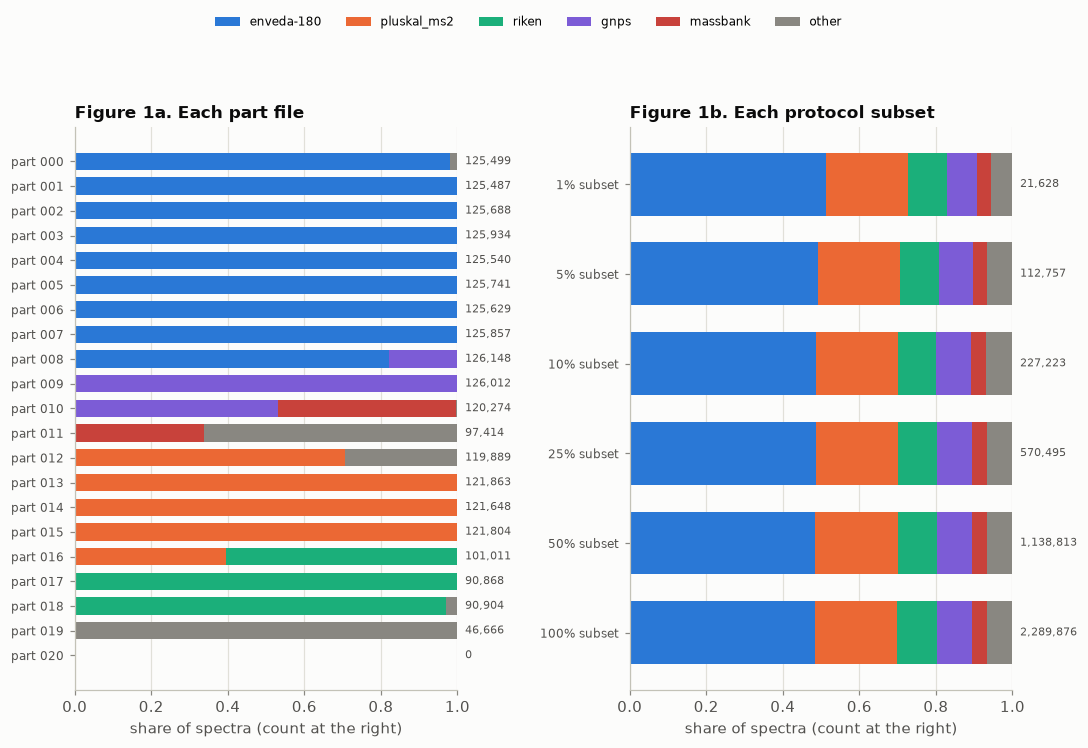

molecules whose spectra are split over more than one part: 26,138 of 270,197


spectra per molecule,molecules,spectra,% of molecules,% of spectra
str,u32,u32,f64,f64
"""1""",17398,17398,6.439,0.760
"""2 to 4""",91813,301178,33.980,13.153
"""5 or more""",160986,1971300,59.581,86.088


In [8]:
# Library mix of every part file and of every protocol subset (training spectra, dev molecules removed).
LIBRARIES = (scan_parts(["inchikey14", "ingest_lib"])
             .join(molecules.lazy().filter(~pl.col("is_dev")).select("inchikey14", "train_subset_rank"), on="inchikey14")
             .collect())
top_libraries = LIBRARIES["ingest_lib"].value_counts(sort=True)["ingest_lib"].head(5).to_list()
LIBRARIES = LIBRARIES.with_columns(pl.when(pl.col("ingest_lib").is_in(top_libraries)).then(pl.col("ingest_lib"))
                                   .otherwise(pl.lit("other")).alias("library"))
LIBRARY_ORDER = top_libraries + (["other"] if (LIBRARIES["library"] == "other").any() else [])


def library_mix(frame: pl.DataFrame) -> dict[str, float]:
    counts = dict(frame.group_by("library").len().iter_rows())
    total = sum(counts.values())
    return {lib: counts.get(lib, 0) / total if total else 0.0 for lib in LIBRARY_ORDER}


panels = {
    "a. Each part file": [(f"part {i:03d}", LIBRARIES.filter(pl.col("part") == i)) for i in range(len(TRAIN_FILES))],
    "b. Each protocol subset": [(f"{f:.0%} subset", LIBRARIES.filter(pl.col("train_subset_rank") < f)) for f in TRAINING_FRACTIONS],
}
colours = [BLUE, ORANGE, AQUA, PURPLE, RED, GREY]
fig, axes = plt.subplots(1, 2, figsize=(11, 0.24 * len(TRAIN_FILES) + 1.6), gridspec_kw={"wspace": 0.45})
for ax, (title, rows) in zip(axes, panels.items()):
    mixes = [library_mix(frame) for _, frame in rows]
    left = np.zeros(len(rows))
    for lib, colour in zip(LIBRARY_ORDER, colours):
        share = np.array([m[lib] for m in mixes])
        ax.barh(range(len(rows)), share, left=left, color=colour, height=0.7, label=lib)
        left += share
    for y, (_, frame) in enumerate(rows):
        ax.text(1.02, y, f"{frame.height:,}", va="center", fontsize=7, color=INK_SOFT)
    ax.set_yticks(range(len(rows)), [label for label, _ in rows], fontsize=8)
    ax.invert_yaxis()
    ax.set_xlim(0, 1)
    ax.set_xlabel("share of spectra (count at the right)")
    ax.set_title(f"Figure 1{title}")
    ax.grid(axis="y", visible=False)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=len(LIBRARY_ORDER), fontsize=8)
plt.show()

per_molecule = LIBRARIES.group_by("inchikey14").agg(pl.len().alias("spectra"), pl.col("part").n_unique().alias("parts"))
print(f"molecules whose spectra are split over more than one part: {(per_molecule['parts'] > 1).sum():,} of {per_molecule.height:,}")
bucket = pl.when(pl.col("spectra") == 1).then(pl.lit("1")).when(pl.col("spectra") < 5).then(pl.lit("2 to 4")).otherwise(pl.lit("5 or more"))
show(per_molecule.group_by(bucket.alias("spectra per molecule")).agg(pl.len().alias("molecules"), pl.col("spectra").sum())
     .with_columns((pl.col("molecules") / pl.col("molecules").sum() * 100).alias("% of molecules"),
                   (pl.col("spectra") / pl.col("spectra").sum() * 100).alias("% of spectra"))
     .sort("spectra per molecule"))
LIBRARIES = LIBRARIES.select("part", "train_subset_rank", "library")      # kept for section 7.4

No minimum number of spectra per molecule: 01 already dropped unusable spectra, and a molecule
measured once still adds a structure the model would otherwise never see. Section 7 tests a
5-spectra minimum as an ablation.

## 2. The target: Morgan fingerprints

The model predicts a 2,048-bit Morgan fingerprint of radius 2 (the ECFP4 equivalent; Rogers and
Hahn, 2010). Each bit says whether some circular substructure, up to two bonds around an atom, is
present, after hashing all such substructures into 2,048 positions. The fingerprints of all molecules
are computed once and cached.

In [9]:
def morgan_bits(smiles: list[str], radius: int, n_bits: int) -> np.ndarray:
    # Packed Morgan fingerprints, n_bits / 8 bytes per molecule. A SMILES RDKit cannot parse gives all zeros.
    generator = rdFingerprintGenerator.GetMorganGenerator(radius=radius, fpSize=n_bits)
    packed = np.zeros((len(smiles), n_bits // 8), dtype=np.uint8)
    for i, smi in enumerate(smiles):
        mol = Chem.MolFromSmiles(smi)
        if mol is not None:
            packed[i] = np.packbits(generator.GetFingerprintAsNumPy(mol))
    return packed


def cached_array(name: str, make) -> np.ndarray:
    path = CACHE_DIR / name
    if path.exists():
        return np.load(path)
    value = make()
    np.save(path, value)
    return value


MOLECULE_KEY = hashlib.sha1("".join(molecules["inchikey14"]).encode()).hexdigest()[:10]   # invalidates stale caches
started = time.perf_counter()
FP = cached_array(f"morgan_r{FP_RADIUS}_{FP_BITS}_{MOLECULE_KEY}.npy",
                  lambda: morgan_bits(molecules["smiles"].to_list(), FP_RADIUS, FP_BITS))


def gather_segments(ptr: np.ndarray, items: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    # For a CSR layout (segment i is ptr[i]:ptr[i+1]): the positions of every element of the chosen segments,
    # and for each position which of `items` it belongs to. Vectorised; used for peaks and for fingerprint bits.
    starts = ptr[items]
    lengths = ptr[items + 1] - starts
    owner = np.repeat(np.arange(len(items)), lengths)
    return owner, np.arange(lengths.sum()) + np.repeat(starts - (np.cumsum(lengths) - lengths), lengths)


@dataclass
class Fingerprints:
    name: str
    packed: np.ndarray         # (molecules, bits / 8)
    ptr: np.ndarray            # the set bits of molecule m are idx[ptr[m]:ptr[m+1]]
    idx: np.ndarray            # int16 bit positions
    n_set: np.ndarray          # bits set per molecule


def fingerprints(name: str, packed: np.ndarray, chunk: int = 20_000) -> Fingerprints:
    parts, counts = [], np.zeros(len(packed), dtype=np.int64)
    for start in range(0, len(packed), chunk):
        rows, cols = np.nonzero(np.unpackbits(packed[start:start + chunk], axis=1))
        parts.append(cols.astype(np.int16))
        counts[start:start + chunk] = np.bincount(rows, minlength=len(packed[start:start + chunk]))
    ptr = np.zeros(len(packed) + 1, dtype=np.int64)
    np.cumsum(counts, out=ptr[1:])
    return Fingerprints(name, packed, ptr, np.concatenate(parts), counts)


FPS = fingerprints(f"morgan r={FP_RADIUS} {FP_BITS}", FP)
BITS_SET = FPS.n_set
print(f"{FP.shape[0]:,} fingerprints ({FP.nbytes / 1e6:.0f} MB packed) in {time.perf_counter() - started:.0f} s; "
      f"{(BITS_SET == 0).sum()} SMILES could not be parsed")


def bit_frequency(mols: np.ndarray, chunk: int = 20_000) -> np.ndarray:
    # Share of the given molecules that set each bit, unpacked a chunk at a time to bound memory.
    counts = np.zeros(FP_BITS)
    for start in range(0, len(mols), chunk):
        counts += np.unpackbits(FP[mols[start:start + chunk]], axis=1).sum(0)
    return counts / max(len(mols), 1)


train_mols = molecules.filter((pl.col("split") == "train") & ~pl.col("is_dev"))["mol"].to_numpy()
FREQ_ALL = bit_frequency(train_mols)

275,689 fingerprints (71 MB packed) in 2 s; 0 SMILES could not be parsed


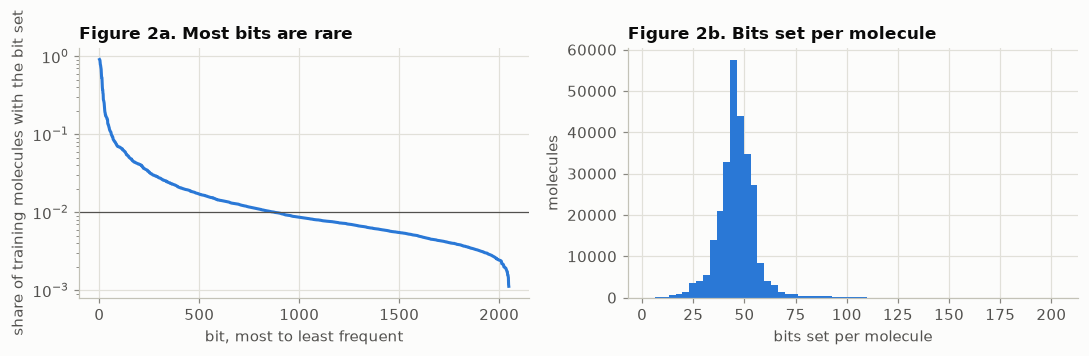

median bits set: 46 of 2048 (2.2%); bits set in under 1% of molecules: 57%; never set: 0
bit accuracy of always predicting 0: 97.75%


In [10]:
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.2))
ranked = np.sort(FREQ_ALL)[::-1]
left.plot(np.arange(1, FP_BITS + 1), np.maximum(ranked, 1e-6), color=BLUE)
left.set_yscale("log")
left.axhline(0.01, color=INK_SOFT, linewidth=0.8)
left.set_xlabel("bit, most to least frequent")
left.set_ylabel("share of training molecules with the bit set")
left.set_title("Figure 2a. Most bits are rare")
right.hist(BITS_SET[train_mols], bins=60, color=BLUE)
right.set_xlabel("bits set per molecule")
right.set_ylabel("molecules")
right.set_title("Figure 2b. Bits set per molecule")
plt.tight_layout()
plt.show()

print(f"median bits set: {np.median(BITS_SET[train_mols]):.0f} of {FP_BITS} ({np.median(BITS_SET[train_mols]) / FP_BITS:.1%}); "
      f"bits set in under 1% of molecules: {(FREQ_ALL < 0.01).mean():.0%}; never set: {(FREQ_ALL == 0).sum()}")
print(f"bit accuracy of always predicting 0: {1 - FREQ_ALL.mean():.2%}")

Predicting all zeros already gets almost every bit right (printed above), so bit accuracy says
nothing. The rare positive bits carry the information; section 5 compares losses that weight them more.

## 3. Candidates

A query molecule is ranked against every molecule in the candidate pool whose mass matches. The
pool is 01's `in_candidates` molecules: the training set's structures without class 3.

### 3.1 The query's mass

The neutral mass comes from the precursor m/z and the adduct, inverting 01's formula
$m/z = (nM + \Delta - z\,m_e)/|z|$, where $n$ is the number of molecules in the ion, $\Delta$ the
mass the adduct adds and $z$ the charge.

In [11]:
# The adduct parser of 01 (section 3), unchanged.
ELEMENT_MASS = {
    "H": 1.00782503207, "C": 12.0, "N": 14.0030740048, "O": 15.99491461956, "S": 31.972071,
    "P": 30.97376163, "F": 18.99840322, "Cl": 34.96885268, "Br": 78.9183371, "I": 126.904473,
    "B": 11.0093054, "Si": 27.9769265325, "As": 74.9215965, "Se": 79.9165213, "Sn": 119.9021947,
    "Li": 7.01600455, "Na": 22.9897692809, "K": 38.96370668, "Mg": 23.9850417, "Ca": 39.96259098,
    "Fe": 55.9349375, "Cu": 62.9295975, "Zn": 63.9291422, "Ag": 106.905097,
}
ELECTRON_MASS = 0.00054857990946
FORMULA = re.compile(r"(?:[A-Z][a-z]?\d*)+")
CHARGE_SUFFIX = re.compile(r"[+-]\d*$")
ELEMENT_COUNT = re.compile(r"([A-Z][a-z]?)(\d*)")
ADDUCT = re.compile(r"\[(\d*)M((?:[+-]\d*[A-Za-z][A-Za-z0-9]*)*)\](\d*)([+-])")
ADDUCT_TERM = re.compile(r"([+-])(\d*)([A-Za-z][A-Za-z0-9]*)")


def formula_mass(formula: str) -> float | None:
    formula = CHARGE_SUFFIX.sub("", formula)
    if not FORMULA.fullmatch(formula):
        return None
    total = 0.0
    for element, count in ELEMENT_COUNT.findall(formula):
        if element not in ELEMENT_MASS:
            return None
        total += ELEMENT_MASS[element] * int(count or 1)
    return total


def adduct_parts(adduct: str) -> tuple[int, float, int] | None:
    match = ADDUCT.fullmatch(adduct)
    if match is None:
        return None
    shift = 0.0
    for sign, multiple, fragment in ADDUCT_TERM.findall(match.group(2)):
        mass = formula_mass(fragment)
        if mass is None:
            return None
        shift += (1 if sign == "+" else -1) * int(multiple or 1) * mass
    charge = int(match.group(3) or 1) * (1 if match.group(4) == "+" else -1)
    return int(match.group(1) or 1), shift, charge


def neutral_masses(precursor_mz: np.ndarray, adducts: list[str]) -> np.ndarray:
    parts = {a: adduct_parts(a) for a in set(adducts)}
    n, shift, charge = (np.array([parts[a][i] if parts[a] else np.nan for a in adducts]) for i in range(3))
    return (precursor_mz * np.abs(charge) - shift + charge * ELECTRON_MASS) / n

### 3.2 Query sets

Three sets of query molecules are scored the same way: **val** (the benchmark), **dev** (model
selection) and **seen**, 1,000 molecules from the smallest training subset whose spectra the model
trained on. The gap between seen and dev is the generalisation gap (section 9).

In [12]:
SPECTRUM_COLUMNS = ["row_id", "inchikey14", "instrument_family", "ionization_mode", "adduct", "is_dimer",
                    "precursor_mz", "collision_energy_ev", "mzs", "intensities"]
ADDUCT_VOCAB = ["[M+H]+", "[M+Na]+", "[M+NH4]+", "[M+K]+", "[M-H2O+H]+", "[M-2H2O+H]+",
                "[M-H]-", "[M+CH2O2-H]-", "[M+Cl]-", "[M-H2O-H]-"]
FAMILIES = ["timsTOF", "Orbitrap/FT", "QTOF/TOF", "triple quadrupole", "ion trap", "other", "unknown"]


def metadata_features(frame: pl.DataFrame) -> np.ndarray:
    # Per spectrum: precursor m/z / 1000, ion mode, adduct (one-hot), dimer, collision energy, instrument family.
    adduct = frame["adduct"]
    energy = frame["collision_energy_ev"].list.mean().cast(pl.Float64).to_numpy()
    family = frame["instrument_family"].fill_null("unknown")
    columns = [frame["precursor_mz"].to_numpy() / 1000, (frame["ionization_mode"] == "positive").to_numpy()]
    columns += [(adduct == a).to_numpy() for a in ADDUCT_VOCAB] + [(~adduct.is_in(ADDUCT_VOCAB)).to_numpy()]
    columns += [frame["is_dimer"].to_numpy(), np.nan_to_num(energy / 100), np.isnan(energy),
                (frame["collision_energy_ev"].list.len().fill_null(0) > 1).to_numpy()]
    columns += [(family == f).to_numpy() for f in FAMILIES]
    return np.column_stack(columns).astype(np.float32)


N_META = len(ADDUCT_VOCAB) + len(FAMILIES) + 7


@dataclass
class SpectraSet:
    # Spectra held as flat arrays: the peaks of spectrum i are offsets[i]:offsets[i+1].
    offsets: np.ndarray        # int64
    mz: np.ndarray             # float32
    intensity: np.ndarray      # float32, relative to the tallest peak
    peak_rank: np.ndarray      # int32, 0 = tallest peak of its spectrum
    precursor: np.ndarray      # float32 precursor m/z
    meta: np.ndarray           # float32, (spectra, N_META)
    mol: np.ndarray            # int32, row of the spectrum's molecule in FP
    subset_rank: np.ndarray    # float32, the molecule's train_subset_rank
    is_tims: np.ndarray        # bool
    is_dimer: np.ndarray       # bool
    row_id: np.ndarray         # int64, row in train.parquet
    part: np.ndarray           # int16, index of the part file (-1 for held-out spectra)

    @property
    def n(self) -> int:
        return len(self.mol)

    def nbytes(self) -> int:
        return sum(value.nbytes for value in vars(self).values())


def load_spectra(frame: pl.DataFrame) -> SpectraSet:
    # frame needs SPECTRUM_COLUMNS plus mol and train_subset_rank, and no spectrum without peaks.
    lengths = frame["mzs"].list.len().to_numpy().astype(np.int64)
    offsets = np.zeros(len(lengths) + 1, dtype=np.int64)
    np.cumsum(lengths, out=offsets[1:])
    rank = frame["intensities"].list.eval(pl.element().rank("ordinal", descending=True) - 1)
    return SpectraSet(
        offsets=offsets,
        mz=frame["mzs"].explode().to_numpy().astype(np.float32),
        intensity=frame["intensities"].explode().to_numpy().astype(np.float32),
        peak_rank=rank.explode().to_numpy().astype(np.int32),
        precursor=frame["precursor_mz"].to_numpy().astype(np.float32),
        meta=metadata_features(frame),
        mol=frame["mol"].to_numpy().astype(np.int32),
        subset_rank=frame["train_subset_rank"].to_numpy().astype(np.float32),
        is_tims=(frame["instrument_family"] == "timsTOF").to_numpy(),
        is_dimer=frame["is_dimer"].to_numpy(),
        row_id=frame["row_id"].to_numpy().astype(np.int64),
        part=(frame["part"].to_numpy().astype(np.int16) if "part" in frame.columns
              else np.full(frame.height, -1, dtype=np.int16)),
    )


MOL_INFO = molecules.select("inchikey14", "mol", "mono_mass", "sim_class", "pool", "train_subset_rank")


@dataclass
class QuerySet:
    name: str
    table: pl.DataFrame        # one row per query molecule
    spectra: SpectraSet        # its spectra, grouped by molecule
    offsets: np.ndarray        # spectra of molecule q are offsets[q]:offsets[q+1]
    cache: dict = field(default_factory=dict)

    @property
    def n(self) -> int:
        return self.table.height


def query_set(name: str, frame: pl.DataFrame) -> QuerySet:
    frame = (frame.filter(pl.col("mzs").list.len() > 0)
             .join(MOL_INFO, on="inchikey14", how="inner").sort("mol", "row_id"))
    frame = frame.with_columns(pl.Series("query_mass", neutral_masses(frame["precursor_mz"].to_numpy(), frame["adduct"].to_list())))
    table = frame.group_by("mol", maintain_order=True).agg(
        pl.col("inchikey14").first(), pl.col("sim_class").first(), pl.col("pool").first(),
        pl.col("mono_mass").first(), pl.len().alias("n_spectra"), pl.col("query_mass").median().alias("mass"))
    offsets = np.concatenate([[0], np.cumsum(table["n_spectra"].to_numpy())]).astype(np.int64)
    return QuerySet(name, table, load_spectra(frame), offsets)


def scan_training() -> pl.LazyFrame:
    return scan_parts(SPECTRUM_COLUMNS)


query_spectrum = (pl.col("instrument_family") == "timsTOF") & ~pl.col("is_dimer")
dev_keys = molecules.filter(pl.col("is_dev")).select("inchikey14")
seen_keys = (molecules.filter((pl.col("split") == "train") & ~pl.col("is_dev") & pl.col("pool").is_in([LIB, ONLY])
                              & (pl.col("train_subset_rank") < min(PLAN["scaling_fractions"])))
             .sort("dev_u").head(N_SEEN).select("inchikey14"))
started = time.perf_counter()
VAL = query_set("val", heldout.filter(pl.col("split") == "val").select(SPECTRUM_COLUMNS))
DEV = query_set("dev", scan_training().filter(query_spectrum).join(dev_keys.lazy(), on="inchikey14", how="semi").collect())
SEEN = query_set("seen", scan_training().filter(query_spectrum).join(seen_keys.lazy(), on="inchikey14", how="semi").collect())
print(f"built in {time.perf_counter() - started:.1f} s")
for qs in (VAL, DEV, SEEN):
    print(f"{qs.name:>4}: {qs.n:,} molecules, {qs.spectra.n:,} spectra")
assert DEV.n > 0, "no dev molecules: DEV_FRACTION is too small for this dataset"

built in 3.1 s
 val: 2,998 molecules, 13,770 spectra
 dev: 1,024 molecules, 4,598 spectra
seen: 1,000 molecules, 4,599 spectra


### 3.3 The mass window

candidate pool: 273,683 molecules


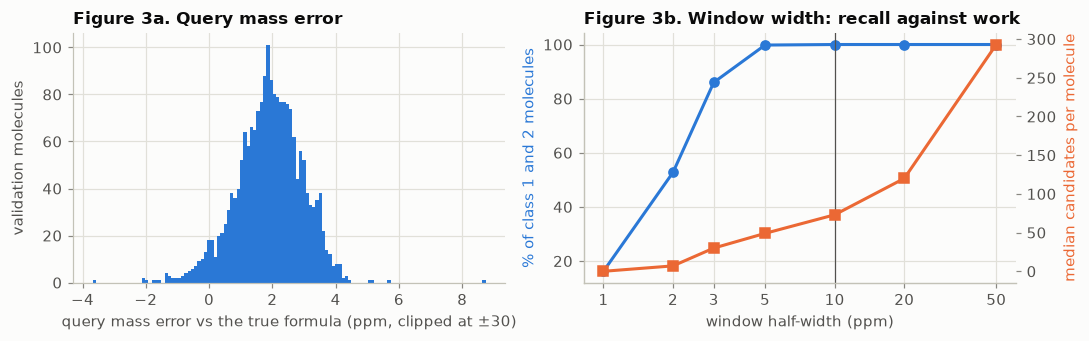

|error| percentiles 50/95/99: [1.94 3.51 4.05] ppm


In [13]:
pool = molecules.filter(pl.col("in_candidates") & pl.col("mono_mass").is_not_null()).select("mol", "mono_mass").sort("mono_mass")
CAND_MASS = pool["mono_mass"].to_numpy()
CAND_MOL = pool["mol"].to_numpy().astype(np.int64)
print(f"candidate pool: {len(CAND_MOL):,} molecules")


def window(qs: QuerySet, ppm: float = PPM_WINDOW) -> tuple[np.ndarray, np.ndarray]:
    # Candidates of query molecule q are CAND_MOL[lo[q]:hi[q]].
    mass = qs.table["mass"].to_numpy()
    return (np.searchsorted(CAND_MASS, mass * (1 - ppm * 1e-6), "left"),
            np.searchsorted(CAND_MASS, mass * (1 + ppm * 1e-6), "right"))


@dataclass
class Candidates:
    mol: np.ndarray            # (C,) candidate molecules, grouped by query molecule
    query: np.ndarray          # (C,) the query molecule each candidate belongs to
    start: np.ndarray          # candidates of query q are start[q]:start[q+1]
    truth: np.ndarray          # (queries,) position of the answer in `mol`, -1 if it is not a candidate
    pair_cand: np.ndarray | None = None   # one entry per set bit of every candidate: which candidate,
    pair_bit: np.ndarray | None = None    # and which bit


def candidates(qs: QuerySet, ppm: float = PPM_WINDOW, fps: Fingerprints | None = None) -> Candidates:
    # The candidate sets of a query set, plus (if fps is given) every candidate's set bits as one flat list.
    # The default window and fingerprints are cached, since dev is re-scored every epoch.
    key = (ppm, fps.name if fps else None)
    hot = ppm == PPM_WINDOW and (fps is None or fps is FPS)
    if hot and key in qs.cache:
        return qs.cache[key]
    lo, hi = window(qs, ppm)
    counts = hi - lo
    query = np.repeat(np.arange(qs.n), counts)
    mol = CAND_MOL[np.arange(counts.sum()) + np.repeat(lo - (np.cumsum(counts) - counts), counts)]
    is_answer = np.flatnonzero(mol == qs.table["mol"].to_numpy()[query])
    truth = np.full(qs.n, -1, dtype=np.int64)
    truth[query[is_answer][::-1]] = is_answer[::-1]          # first occurrence wins
    result = Candidates(mol, query, np.concatenate([[0], np.cumsum(counts)]), truth)
    if fps is not None:
        owner, pos = gather_segments(fps.ptr, mol)
        result.pair_cand, result.pair_bit = owner.astype(np.int32), fps.idx[pos]
    if hot:
        qs.cache[key] = result
    return result


def truth_in_window(qs: QuerySet, ppm: float) -> np.ndarray:
    return candidates(qs, ppm).truth >= 0


answerable = VAL.table["sim_class"].is_in([1, 2]).to_numpy()
ppm_error = ((VAL.table["mass"] - VAL.table["mono_mass"]) / VAL.table["mono_mass"] * 1e6).to_numpy()[answerable]
windows = [1, 2, 3, 5, 10, 20, 50]
recall = [truth_in_window(VAL, w)[answerable].mean() for w in windows]
sizes = [np.median(np.subtract(*window(VAL, w)[::-1])) for w in windows]

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.2))
left.hist(np.clip(ppm_error, -30, 30), bins=120, color=BLUE)
left.set_xlabel("query mass error vs the true formula (ppm, clipped at ±30)")
left.set_ylabel("validation molecules")
left.set_title("Figure 3a. Query mass error")
right.plot(windows, np.array(recall) * 100, marker="o", color=BLUE, label="answer inside the window (%)")
right.set_xscale("log")
right.set_xticks(windows, [str(w) for w in windows])
right.minorticks_off()
right.set_xlabel("window half-width (ppm)")
right.set_ylabel("% of class 1 and 2 molecules", color=BLUE)
twin = right.twinx()
twin.plot(windows, sizes, marker="s", color=ORANGE)
twin.set_ylabel("median candidates per molecule", color=ORANGE)
twin.grid(False)
right.axvline(PPM_WINDOW, color=INK_SOFT, linewidth=0.8)
right.set_title("Figure 3b. Window width: recall against work")
plt.tight_layout()
plt.show()
print(f"|error| percentiles 50/95/99: {np.nanpercentile(np.abs(ppm_error), [50, 95, 99]).round(2)} ppm")

The window is a ceiling on every method: a molecule whose answer falls outside it scores zero. Past
the point where recall flattens, a wider window only adds candidates.

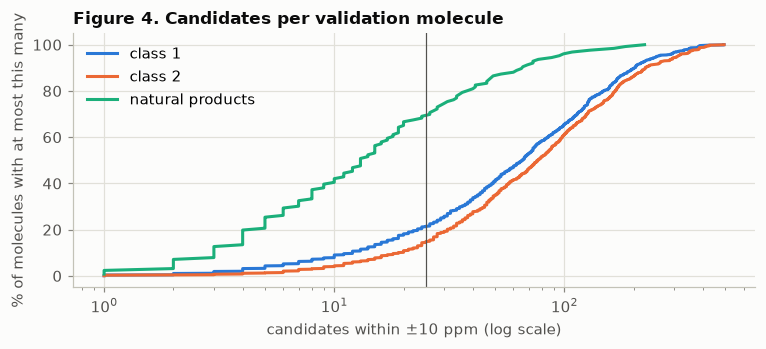

sim_class,molecules,median candidates,% with more than 25,max
i8,u32,f64,f64,i64
1,1038,66.000,78.516,494
2,961,77.000,85.120,494
3,999,82.000,83.584,494


In [14]:
lo, hi = window(VAL)
VAL_SIZES = VAL.table.with_columns(pl.Series("n_candidates", hi - lo))
fig, ax = plt.subplots(figsize=(8, 3))
for name, cond in [("class 1", pl.col("sim_class") == 1), ("class 2", pl.col("sim_class") == 2),
                   ("natural products", pl.col("pool") == NP)]:
    values = np.sort(VAL_SIZES.filter(cond)["n_candidates"].to_numpy())
    if len(values):
        ax.plot(np.maximum(values, 1), np.arange(1, len(values) + 1) / len(values) * 100, color=GROUP_COLOURS[name], label=name)
ax.axvline(TOP_K, color=INK_SOFT, linewidth=0.8)
ax.set_xscale("log")
ax.set_xlabel(f"candidates within ±{PPM_WINDOW:g} ppm (log scale)")
ax.set_ylabel("% of molecules with at most this many")
ax.set_title("Figure 4. Candidates per validation molecule")
ax.legend()
plt.show()
show(VAL_SIZES.group_by("sim_class").agg(
    pl.len().alias("molecules"), pl.col("n_candidates").median().alias("median candidates"),
    (pl.col("n_candidates") > TOP_K).mean().mul(100).alias(f"% with more than {TOP_K}"),
    pl.col("n_candidates").max().alias("max")).sort("sim_class"))

### 3.4 Ranking with ties, and two baselines

A model can give two candidates exactly the same score, for example two molecules with identical
fingerprints. If $g$ candidates score above the answer and $t$ others tie with it, its rank is
equally likely to be any of $g+1,\dots,g+t+1$, so

$$\mathbb{E}[\mathrm{RR}] = \frac{1}{t+1}\sum_{r=g+1}^{g+t+1}\frac{\mathbf{1}[r\le 25]}{r}.$$

Breaking ties by list order instead would reward whichever candidate the data happened to list
first. `rank_queries` below scores every method; the two baselines need no spectrum at all.

In [15]:
HARMONIC = np.concatenate([[0.0], np.cumsum(1.0 / np.arange(1, 1_000_001))])


def packed_tanimoto(a: np.ndarray, b: np.ndarray) -> np.ndarray:
    # Binary Tanimoto similarity between matching rows of two packed fingerprint matrices.
    inter = np.bitwise_count(a & b).sum(1)
    return inter / np.maximum(np.bitwise_count(a | b).sum(1), 1)


def rank_queries(qs: QuerySet, score, ppm: float = PPM_WINDOW, keep_top: int = 0, fps: Fingerprints = None):
    # score(candidates) returns one score per candidate (higher is better). All query molecules are ranked at once:
    # g = candidates scoring above the answer, t = others tied with it, per molecule, by bincount over the flat arrays.
    c = candidates(qs, ppm, fps if fps is not None else FPS)
    s = np.asarray(score(c), dtype=np.float64)
    n, n_cand = qs.n, np.diff(c.start)
    has = c.truth >= 0
    answer = np.full(n, np.nan)
    answer[has] = s[c.truth[has]]
    g = np.bincount(c.query, weights=s > answer[c.query], minlength=n)
    t = np.where(has, np.bincount(c.query, weights=s == answer[c.query], minlength=n) - 1, 0)
    last = np.minimum(g + t + 1, TOP_K).astype(np.int64)
    first = np.minimum(g + 1, TOP_K + 1).astype(np.int64)
    rr = np.where(has & (g + 1 <= TOP_K), (HARMONIC[last] - HARMONIC[first - 1]) / (t + 1), 0.0)
    hit = {k: np.where(has, np.clip(np.minimum(g + t + 1, k) - g, 0, None) / (t + 1), 0.0) for k in (1, 5, 25)}
    order = np.lexsort((-s, c.query))           # by query, best score first; segment q starts at c.start[q]
    nonempty = n_cand > 0
    top1 = np.full(n, np.nan)
    truth_mol = qs.table["mol"].to_numpy()
    top1[nonempty] = packed_tanimoto(FP[truth_mol[nonempty]], FP[c.mol[order[c.start[:-1][nonempty]]]])
    result = pl.concat([qs.table.select("inchikey14", "mol", "sim_class", "pool", "n_spectra"), pl.DataFrame({
        "n_candidates": n_cand, "truth_in_set": has, "rank": np.where(has, g + 1 + t / 2, np.nan), "rr": rr,
        "hit1": hit[1], "hit5": hit[5], "hit25": hit[25], "top1_tanimoto": top1})], how="horizontal")
    if not keep_top:
        return result
    kept = np.minimum(n_cand, keep_top)
    owner, pos = gather_segments(c.start, np.arange(n))
    pos = pos[(pos - c.start[owner]) < kept[owner]]
    owner = c.query[order[pos]]
    tops = pl.DataFrame({"mol": truth_mol[owner].astype(np.int64), "rank": pos - c.start[owner] + 1,
                         "candidate_mol": c.mol[order[pos]].astype(np.int64), "score": s[order[pos]]})
    return result, tops


EVAL_GROUPS = {"class 1": pl.col("sim_class") == 1, "class 2": pl.col("sim_class") == 2,
               "natural products": pl.col("pool") == NP, "classes 1+2": pl.col("sim_class").is_in([1, 2])}


def summarise(per_molecule: pl.DataFrame, groups: dict = EVAL_GROUPS) -> dict:
    out = {}
    for name, cond in groups.items():
        g = per_molecule.filter(cond)
        mrr, low, high = bootstrap(g["rr"].to_numpy())
        out[name] = {"molecules": g.height, "mrr": mrr, "mrr_low": low, "mrr_high": high,
                     **{h: float(g[h].mean()) if g.height else math.nan for h in ("hit1", "hit5", "hit25")},
                     "answer_in_window": float(g["truth_in_set"].mean()) if g.height else math.nan}
    c3 = per_molecule.filter(pl.col("sim_class") == 3)
    out["class 3"] = {"molecules": c3.height, "top1_tanimoto": float(c3["top1_tanimoto"].mean()) if c3.height else math.nan}
    return out


def summary_table(summaries: dict[str, dict]) -> pl.DataFrame:
    rows = []
    for method, s in summaries.items():
        for group in EVAL_GROUPS:
            g = s[group]
            rows.append({"method": method, "group": group, "molecules": g["molecules"], "MRR@25": g["mrr"],
                         "95% CI": f"{g['mrr_low']:.3f} to {g['mrr_high']:.3f}", "hit@1": g["hit1"], "hit@5": g["hit5"],
                         "hit@25": g["hit25"]})
    return pl.DataFrame(rows)


# Baselines: every candidate tied (random order), and nearest formula mass first (isomers tie).
VAL_MASS, MONO_MASS = VAL.table["mass"].to_numpy(), molecules["mono_mass"].to_numpy()
BASELINES = {
    "random order": rank_queries(VAL, lambda c: np.zeros(len(c.mol))),
    "nearest mass": rank_queries(VAL, lambda c: -np.abs(MONO_MASS[c.mol] - VAL_MASS[c.query])),
}
show(summary_table({k: summarise(v) for k, v in BASELINES.items()}).filter(pl.col("group").is_in(["class 1", "class 2"])))

method,group,molecules,MRR@25,95% CI,hit@1,hit@5,hit@25
str,str,i64,f64,str,f64,f64,f64
"""random order""","""class 1""",1038,0.110,"""0.102 to 0.118""",0.040,0.167,0.493
"""random order""","""class 2""",961,0.085,"""0.078 to 0.091""",0.028,0.122,0.438
"""nearest mass""","""class 1""",1038,0.175,"""0.162 to 0.189""",0.076,0.274,0.626
"""nearest mass""","""class 2""",961,0.143,"""0.131 to 0.156""",0.056,0.215,0.599


### 3.5 How far can a fingerprint get?

Even a perfect predictor, one that outputs the answer's exact fingerprint, ties with every candidate
that has the same fingerprint (positional isomers can). Scoring that oracle gives the ceiling
of the whole fingerprint approach, for each choice of fingerprint, before any training.

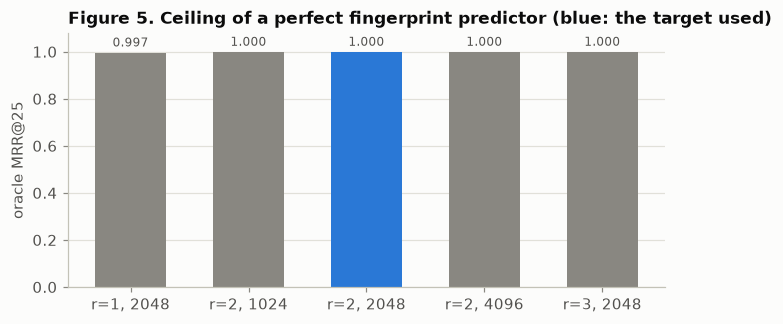

radius,bits,"oracle MRR@25, classes 1+2",% of answerable molecules tied with another candidate
i64,i64,f64,f64
1,2048,0.997,1.251
2,1024,1.000,0.100
2,2048,1.000,0.100
2,4096,1.000,0.100
3,2048,1.000,0.050


In [16]:
FP_SETTINGS = [(1, 2048), (2, 1024), (2, 2048), (2, 4096), (3, 2048)]


def oracle_score(qs: QuerySet, fps: Fingerprints):
    # Score = binary Tanimoto between each candidate and the answer: what a perfect predictor would give.
    truth = qs.table["mol"].to_numpy()
    def score(c):
        answer_bits = np.unpackbits(fps.packed[truth], axis=1)
        inter = np.bincount(c.pair_cand, weights=answer_bits[c.query[c.pair_cand], c.pair_bit], minlength=len(c.mol))
        return inter / np.maximum(fps.n_set[truth][c.query] + fps.n_set[c.mol] - inter, 1)
    return score


c_val = candidates(VAL)
needed = np.unique(np.concatenate([c_val.mol, VAL.table["mol"].to_numpy()]))
smiles_all = molecules["smiles"].to_list()
ceiling_rows, ORACLE, ORACLE_FPS = [], {}, {}
for radius, n_bits in FP_SETTINGS:
    if (radius, n_bits) == (FP_RADIUS, FP_BITS):
        fps = FPS
    else:
        needed_key = hashlib.sha1(needed.tobytes()).hexdigest()[:10]
        packed = cached_array(f"morgan_r{radius}_{n_bits}_{needed_key}.npy",
                              lambda: morgan_bits([smiles_all[i] for i in needed], radius, n_bits))
        full = np.zeros((molecules.height, n_bits // 8), dtype=np.uint8)
        full[needed] = packed
        fps = fingerprints(f"morgan r={radius} {n_bits}", full)
    result = rank_queries(VAL, oracle_score(VAL, fps), fps=fps)
    ORACLE[(radius, n_bits)], ORACLE_FPS[(radius, n_bits)] = result, fps
    answer = result.filter(pl.col("sim_class").is_in([1, 2]))
    ceiling_rows.append({"radius": radius, "bits": n_bits, "oracle MRR@25, classes 1+2": answer["rr"].mean(),
                         "% of answerable molecules tied with another candidate":
                             (answer.filter(pl.col("truth_in_set"))["rank"] > 1).mean() * 100})
CEILING = pl.DataFrame(ceiling_rows)

fig, ax = plt.subplots(figsize=(7, 3))
labels = [f"r={r}, {b}" for r, b in FP_SETTINGS]
bars = ax.bar(labels, CEILING["oracle MRR@25, classes 1+2"], width=0.6,
              color=[BLUE if (r, b) == (FP_RADIUS, FP_BITS) else GREY for r, b in FP_SETTINGS])
ax.bar_label(bars, fmt="%.3f", padding=2, fontsize=8, color=INK_SOFT)
ax.set_ylim(0, 1.08)
ax.set_ylabel("oracle MRR@25")
ax.set_title("Figure 5. Ceiling of a perfect fingerprint predictor (blue: the target used)")
ax.grid(axis="x", visible=False)
plt.show()
show(CEILING)

The gap between the ceiling and 1 is lost to the window (answers outside it) and to fingerprint
collisions. A larger radius or more bits raises the ceiling but gives the network more, rarer bits
to learn.

## 4. From spectra to batches

A 0.1 Da binned spectrum has 15,026 positions, of which a few dozen are filled. The first layer of
an MLP multiplies that vector by a weight matrix $E$. `nn.EmbeddingBag` computes the same product
from the filled positions only, as a weighted sum of the rows of $E$ for the peaks' bins:

$$h^{(0)} = \sum_{\text{peaks } i} w_i\, E_{b(i)}, \qquad b(i) = \lfloor m_i / \Delta \rfloor, \qquad w_i = \frac{\sqrt{I_i}}{\lVert \sqrt{I}\rVert_2}.$$

Cost and memory then grow with the number of peaks, not the number of bins, which is what allows
0.01 Da bins (150,251 positions) and 1000 times the data. Peaks are stored once as flat arrays;
bins, intensity transforms, peak limits and neutral losses are applied per batch, so one loaded
dataset serves every configuration.

In [17]:
def n_bins(cfg: Config) -> int:
    return int(math.ceil(MAX_FRAGMENT_MZ / cfg.bin_width)) + 1


def n_inputs(cfg: Config) -> int:
    return n_bins(cfg) * (2 if cfg.neutral_losses else 1)


def intensity_weight(intensity: np.ndarray, kind: str) -> np.ndarray:
    if kind == "raw":
        return intensity
    if kind == "sqrt":
        return np.sqrt(intensity)
    if kind == "log":
        return np.log1p(100 * intensity)        # 0.5% -> 0.41, 100% -> 4.62
    if kind == "binary":
        return np.ones_like(intensity)
    raise ValueError(kind)


def featurize(ss: SpectraSet, rows: np.ndarray, cfg: Config):
    # Sparse input for nn.EmbeddingBag: input indices, bag offsets and per-input weights for spectra `rows`.
    bag, pos = gather_segments(ss.offsets, rows)
    if cfg.top_peaks:
        keep = ss.peak_rank[pos] < cfg.top_peaks
        bag, pos = bag[keep], pos[keep]
    mz = ss.mz[pos].astype(np.float64)
    width, size = cfg.bin_width, n_bins(cfg)
    index = np.minimum((mz / width + 1e-6).astype(np.int64), size - 1)
    weight = intensity_weight(ss.intensity[pos], cfg.intensity)
    if cfg.neutral_losses:
        loss = ss.precursor[rows][bag] - mz
        ok = loss > 0.5                       # skip the precursor peak itself
        bag = np.concatenate([bag, bag[ok]])
        index = np.concatenate([index, size + np.minimum((loss[ok] / width + 1e-6).astype(np.int64), size - 1)])
        weight = np.concatenate([weight, weight[ok]])
        order = np.argsort(bag, kind="stable")
        bag, index, weight = bag[order], index[order], weight[order]
    norm = np.sqrt(np.bincount(bag, weights=weight * weight, minlength=len(rows)))
    weight = weight / np.maximum(norm[bag], 1e-12)
    offsets = np.concatenate([[0], np.cumsum(np.bincount(bag, minlength=len(rows)))[:-1]])
    return index, offsets.astype(np.int64), weight.astype(np.float32)


def batch_tensors(ss: SpectraSet, rows: np.ndarray, cfg: Config, device=DEVICE):
    index, offsets, weight = featurize(ss, rows, cfg)
    meta = torch.from_numpy(ss.meta[rows]).to(device) if cfg.metadata else None
    return (torch.from_numpy(index).to(device), torch.from_numpy(offsets).to(device),
            torch.from_numpy(weight).to(device), meta)


def batch_targets(ss: SpectraSet, rows: np.ndarray, device=DEVICE) -> torch.Tensor:
    return torch.from_numpy(np.unpackbits(FP[ss.mol[rows]], axis=1)).to(device).float()


_TRAINING = {"fraction": 0.0, "data": None}


def training_data(fraction: float) -> SpectraSet:
    # Loads the training spectra once, at the largest fraction this RUN_SIZE needs; smaller subsets are masks on it.
    if _TRAINING["data"] is None or _TRAINING["fraction"] < fraction:
        load_fraction = max(fraction, FINAL_FRACTION)
        started = time.perf_counter()
        frame = (protocol_subset(load_fraction, SPECTRUM_COLUMNS).filter(pl.col("mzs").list.len() > 0)
                 .join(MOL_INFO.lazy().select("inchikey14", "mol", "train_subset_rank"), on="inchikey14", how="inner")
                 .collect())
        _TRAINING.update(fraction=load_fraction, data=None)
        gc.collect()
        _TRAINING["data"] = load_spectra(frame)
        del frame
        gc.collect()
        ss = _TRAINING["data"]
        print(f"loaded {ss.n:,} training spectra (fraction {load_fraction}) in {time.perf_counter() - started:.0f} s; "
              f"{ss.nbytes() / 1e6:,.0f} MB, {ss.nbytes() / ss.n:.0f} bytes per spectrum")
    return _TRAINING["data"]


def training_rows(train: SpectraSet, cfg: Config) -> np.ndarray:
    keep = train.subset_rank < cfg.fraction
    if cfg.part >= 0:
        keep &= train.part == cfg.part
    if cfg.instruments == "timsTOF":
        keep &= train.is_tims
    elif cfg.instruments == "other":
        keep &= ~train.is_tims
    if cfg.drop_dimers:
        keep &= ~train.is_dimer
    rows = np.flatnonzero(keep)
    if cfg.min_spectra:           # only molecules with at least min_spectra spectra in this training set
        counts = np.bincount(train.mol[rows])
        rows = rows[counts[train.mol[rows]] >= cfg.min_spectra]
    if cfg.one_per_molecule:      # one spectrum per molecule, picked by a hash of its row id so every run agrees
        order = np.argsort((train.row_id[rows].astype(np.uint64) * np.uint64(0x9E3779B97F4A7C15)) >> np.uint64(16))
        rows = rows[order]
        _, first = np.unique(train.mol[rows], return_index=True)
        rows = np.sort(rows[first])
    return rows

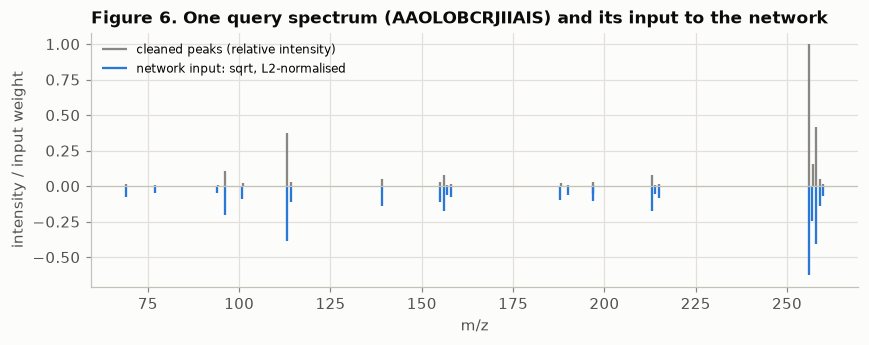

24 non-zero inputs out of 15,026; meta features: 24


In [18]:
# One validation spectrum as the network sees it.
example = 0
rows = np.array([example])
index, offsets, weight = featurize(VAL.spectra, rows, BASE)
peaks = slice(VAL.spectra.offsets[example], VAL.spectra.offsets[example + 1])
fig, ax = plt.subplots(figsize=(9, 3))
ax.vlines(VAL.spectra.mz[peaks], 0, VAL.spectra.intensity[peaks], color=GREY, linewidth=1.5, label="cleaned peaks (relative intensity)")
ax.vlines(index * BASE.bin_width, 0, -weight, color=BLUE, linewidth=1.5, label=f"network input: {BASE.intensity}, L2-normalised")
ax.axhline(0, color="#c3c2b7", linewidth=0.8)
ax.set_xlabel("m/z")
ax.set_ylabel("intensity / input weight")
ax.set_title(f"Figure 6. One query spectrum ({VAL.table['inchikey14'][0]}) and its input to the network")
ax.legend(fontsize=8, loc="upper left")
plt.show()
print(f"{len(index)} non-zero inputs out of {n_inputs(BASE):,}; meta features: {N_META}")

## 5. The model, the losses and the scores

### 5.1 The maths

**Network.** After the sparse input layer, residual blocks with layer norm (a standard MLP block):

$$h^{(0)} \leftarrow \mathrm{Dropout}\big(\mathrm{GELU}(\mathrm{LN}(h^{(0)} + W_m m))\big), \qquad
h^{(l+1)} = h^{(l)} + \mathrm{Dropout}\big(\mathrm{GELU}(W_l\,\mathrm{LN}(h^{(l)}) + b_l)\big),$$

$$z = W_{\text{out}}\,\mathrm{LN}(h^{(L)}) + b_{\text{out}}, \qquad p = \sigma(z) \in (0,1)^{2048},$$

where $m$ is the metadata vector. $b_{\text{out}}$ starts at $\log\frac{f_j}{1-f_j}$, the log-odds of
each bit's training frequency $f_j$, so training starts from the base rates instead of $p=0.5$.

**Losses** (mean over a batch; $y\in\{0,1\}^{2048}$ is the answer's fingerprint):

| Loss | Per bit, or per spectrum | Idea |
| --- | --- | --- |
| BCE | $-[y_j\log p_j + (1-y_j)\log(1-p_j)]$ | Each bit an independent yes/no; $\partial/\partial z_j = p_j - y_j$ |
| Weighted BCE | positives multiplied by $w_j=\min\big(\sqrt{(1-f_j)/f_j},\,100\big)$ | Up-weights rare bits; the square root avoids over-predicting them |
| Focal (Lin et al., 2017) | $(1-p_{t})^{2}\times$ BCE, $p_t$ the probability given to the true value | Down-weights the many easy zeros |
| Soft Tanimoto | $1 - \frac{\sum_j p_j y_j}{\sum_j p_j + \sum_j y_j - \sum_j p_j y_j}$ | Trains the similarity that ranks candidates |
| BCE + Tanimoto | BCE $+\,0.1\times$ soft Tanimoto | Both; 0.1 makes the gradients similar in size |

Why the weighting matters (figure 2): at the start $p_j = f_j$, so the ~2,000 zero bits of a molecule
give gradients summing to $\sum_j f_j$ and its ~40 one bits give $\sum_{j:y_j=1}(f_j-1)\approx-40$.
Since $\sum_j f_j$ is the mean number of bits set, the two start level; the zeros are then learned
first and training is left to the few rare positives. The weighted and focal losses change that
balance on purpose.

**Scoring a candidate** $c$ with fingerprint $y_c$:

* Tanimoto: $T(p, y_c) = \frac{p\cdot y_c}{\sum p + \sum y_c - p\cdot y_c}$ (the default)
* cosine: $\frac{p\cdot y_c}{\lVert p\rVert\,\lVert y_c\rVert}$
* Bernoulli log-likelihood: $\log P(y_c\mid p) = \sum_j y_{cj}\log p_j + (1-y_{cj})\log(1-p_j)
  = \underbrace{\textstyle\sum_j \log(1-p_j)}_{\text{same for every candidate}} + \sum_j y_{cj}\,z_j$.
  Since $\log\frac{p}{1-p}=z$, ranking by likelihood is ranking by $y_c\cdot z$, a dot product with
  the logits. It is the right score if the bits are independent and $p$ is calibrated (figure 10).

**Several spectra per molecule.** Average $p$ over the molecule's spectra (default), average $z$
(which adds the log-likelihoods: a product of experts), or score each spectrum and keep each
candidate's best score.

### 5.2 The code

In [19]:
class FingerprintMLP(nn.Module):
    def __init__(self, n_in: int, n_meta: int, width: int, depth: int, dropout: float, prior: np.ndarray, sparse: bool):
        super().__init__()
        self.inputs = nn.EmbeddingBag(n_in, width, mode="sum", sparse=sparse)
        nn.init.normal_(self.inputs.weight, std=0.1)
        self.meta = nn.Linear(n_meta, width) if n_meta else None
        self.norm_in = nn.LayerNorm(width)
        self.blocks = nn.ModuleList([nn.Sequential(nn.LayerNorm(width), nn.Linear(width, width), nn.GELU(), nn.Dropout(dropout))
                                     for _ in range(depth - 1)])
        self.drop = nn.Dropout(dropout)
        self.norm_out = nn.LayerNorm(width)
        self.out = nn.Linear(width, FP_BITS)
        prior = np.clip(prior, 1e-4, 1 - 1e-4)
        with torch.no_grad():
            self.out.bias.copy_(torch.from_numpy(np.log(prior / (1 - prior))).float())

    def forward(self, index, offsets, weight, meta=None):
        h = self.inputs(index, offsets, per_sample_weights=weight)
        if self.meta is not None:
            h = h + self.meta(meta)
        h = self.drop(F.gelu(self.norm_in(h)))
        for block in self.blocks:
            h = h + block(h)
        return self.out(self.norm_out(h))


def build_model(cfg: Config, prior: np.ndarray, device=DEVICE) -> FingerprintMLP:
    return FingerprintMLP(n_inputs(cfg), N_META if cfg.metadata else 0, cfg.width, cfg.depth, cfg.dropout,
                          prior, cfg.sparse_grad).to(device)


def make_optimisers(model: FingerprintMLP, cfg: Config) -> list:
    if not cfg.sparse_grad:
        return [torch.optim.AdamW(model.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)]
    dense = [p for name, p in model.named_parameters() if not name.startswith("inputs.")]
    return [torch.optim.SparseAdam(list(model.inputs.parameters()), lr=cfg.lr),
            torch.optim.AdamW(dense, lr=cfg.lr, weight_decay=cfg.weight_decay)]


def soft_tanimoto(p: torch.Tensor, y: torch.Tensor) -> torch.Tensor:
    inter = (p * y).sum(1)
    return inter / (p.sum(1) + y.sum(1) - inter).clamp_min(1e-6)


def loss_fn(logits: torch.Tensor, y: torch.Tensor, kind: str, pos_weight: torch.Tensor) -> torch.Tensor:
    if kind == "bce":
        return F.binary_cross_entropy_with_logits(logits, y)
    if kind == "wbce":
        return F.binary_cross_entropy_with_logits(logits, y, pos_weight=pos_weight)
    if kind == "focal":
        p = torch.sigmoid(logits)
        p_true = p * y + (1 - p) * (1 - y)
        return ((1 - p_true) ** 2 * F.binary_cross_entropy_with_logits(logits, y, reduction="none")).mean()
    tanimoto_loss = (1 - soft_tanimoto(torch.sigmoid(logits), y)).mean()
    if kind == "tanimoto":
        return tanimoto_loss
    if kind == "bce+tanimoto":
        return F.binary_cross_entropy_with_logits(logits, y) + 0.1 * tanimoto_loss
    raise ValueError(kind)


@torch.no_grad()
def predict(model: FingerprintMLP, ss: SpectraSet, cfg: Config, batch_size: int = 4096) -> np.ndarray:
    model.eval()
    logits = np.empty((ss.n, FP_BITS), dtype=np.float32)
    for start in range(0, ss.n, batch_size):
        rows = np.arange(start, min(start + batch_size, ss.n))
        logits[rows] = model(*batch_tensors(ss, rows, cfg)).float().cpu().numpy()
    return logits


def sigmoid(z):
    return 1 / (1 + np.exp(-z))


def aggregate_logits(qs: QuerySet, logits: np.ndarray, how: str) -> np.ndarray:
    # One row of logits per query molecule from the rows of its spectra.
    n_spectra = np.diff(qs.offsets)[:, None]
    if how == "mean_logit":
        return np.add.reduceat(logits, qs.offsets[:-1], axis=0) / n_spectra
    p = np.clip(np.add.reduceat(sigmoid(logits), qs.offsets[:-1], axis=0) / n_spectra, 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))


def fingerprint_scores(c: Candidates, z: np.ndarray, scoring: str) -> np.ndarray:
    # z: logits, one row per query molecule. Every candidate's score from the flat list of its set bits:
    # p . y_c is the sum of p over the candidate's set bits (a bincount), never a dense candidate matrix.
    rows = c.query[c.pair_cand]
    if scoring == "loglik":
        return np.bincount(c.pair_cand, weights=z[rows, c.pair_bit], minlength=len(c.mol))
    p = sigmoid(z)
    inter = np.bincount(c.pair_cand, weights=p[rows, c.pair_bit], minlength=len(c.mol))
    n_set = FPS.n_set[c.mol]
    if scoring == "tanimoto":
        return inter / np.maximum(p.sum(1)[c.query] + n_set - inter, 1e-9)
    if scoring == "cosine":
        return inter / (np.linalg.norm(p, axis=1)[c.query] * np.sqrt(n_set) + 1e-9)
    raise ValueError(scoring)


def model_score(qs: QuerySet, logits: np.ndarray, scoring: str = "tanimoto", aggregate: str = "mean_prob"):
    def score(c: Candidates) -> np.ndarray:
        if aggregate != "max":
            return fingerprint_scores(c, aggregate_logits(qs, logits, aggregate), scoring)
        n_spectra, best = np.diff(qs.offsets), None
        for j in range(int(n_spectra.max())):      # j-th spectrum of every molecule (its last one if it has fewer)
            s = fingerprint_scores(c, logits[qs.offsets[:-1] + np.minimum(j, n_spectra - 1)], scoring)
            best = s if best is None else np.maximum(best, s)
        return best
    return score


def bce_numpy(logits: np.ndarray, ss: SpectraSet) -> float:
    y = np.unpackbits(FP[ss.mol], axis=1).astype(np.float32)
    return float((np.maximum(logits, 0) - logits * y + np.log1p(np.exp(-np.abs(logits)))).mean())

In [20]:
EPOCH_HOOK = None    # section 13 sets this to record curves on the group split after every epoch


def fit(cfg: Config, train: SpectraSet):
    torch.manual_seed(cfg.seed)
    rng = np.random.default_rng(cfg.seed)
    rows = training_rows(train, cfg)
    mols = np.unique(train.mol[rows])
    freq = (bit_frequency(mols) * len(mols) + 1) / (len(mols) + 2)
    model = build_model(cfg, freq)
    pos_weight = torch.tensor(np.clip(np.sqrt((1 - freq) / freq), 1, 100), dtype=torch.float32, device=DEVICE)
    optimisers = make_optimisers(model, cfg)
    steps = math.ceil(len(rows) / cfg.batch_size)
    total, warmup = steps * cfg.max_epochs, max(1, min(1000, steps * cfg.max_epochs // 20))
    factor = lambda step: min(1.0, (step + 1) / warmup) * (0.05 + 0.475 * (1 + math.cos(math.pi * min(step, total) / total)))
    schedulers = [torch.optim.lr_scheduler.LambdaLR(o, factor) for o in optimisers]
    process = psutil.Process()
    peak_rss = process.memory_info().rss
    if DEVICE.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    history, best, anchor, best_state, waited, n_inputs_seen = [], -1.0, -1.0, None, 0, 0
    for epoch in range(1, cfg.max_epochs + 1):
        model.train()
        order = rng.permutation(rows)
        started, feature_seconds = time.perf_counter(), 0.0
        loss_sum = torch.zeros((), device=DEVICE)
        for start in range(0, len(order), cfg.batch_size):
            batch = order[start:start + cfg.batch_size]
            t0 = time.perf_counter()
            x, y = batch_tensors(train, batch, cfg), batch_targets(train, batch)
            feature_seconds += time.perf_counter() - t0
            if epoch == 1:
                n_inputs_seen += len(x[0])
            loss = loss_fn(model(*x), y, cfg.loss, pos_weight)
            for o in optimisers:
                o.zero_grad(set_to_none=True)
            loss.backward()
            for o in optimisers:
                o.step()
            for s in schedulers:
                s.step()
            loss_sum += loss.detach()
        if DEVICE.type == "cuda":
            torch.cuda.synchronize()
        seconds = time.perf_counter() - started
        dev_logits = predict(model, DEV.spectra, cfg)
        dev_mrr = float(rank_queries(DEV, model_score(DEV, dev_logits))["rr"].mean())
        history.append({"epoch": epoch, "train_loss": loss_sum.item() / steps, "dev_bce": bce_numpy(dev_logits, DEV.spectra),
                        "dev_mrr": dev_mrr, "seconds": seconds, "feature_seconds": feature_seconds,
                        "spectra_seen": epoch * len(rows)})
        if EPOCH_HOOK is not None:    # evaluation only (predict() runs in eval mode); training is unchanged
            history[-1].update(EPOCH_HOOK(model, cfg))
        peak_rss = max(peak_rss, process.memory_info().rss)
        if dev_mrr > best:            # keep the best epoch's weights
            best = dev_mrr
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        if dev_mrr > anchor + MIN_DELTA:
            anchor, waited = dev_mrr, 0
        else:
            waited += 1
            if waited >= cfg.patience:
                break
    model.load_state_dict(best_state)
    history = pl.DataFrame(history)
    params = sum(p.numel() for p in model.parameters())
    inputs_per_spectrum = n_inputs_seen / len(rows)
    active = inputs_per_spectrum * cfg.width + (params - model.inputs.weight.numel())
    stats = {"spectra": int(len(rows)), "molecules": int(len(mols)), "epochs": history.height,
             "best_epoch": int(history["epoch"][int(history["dev_mrr"].arg_max())]),
             "seconds": float(history["seconds"].sum()), "seconds_per_epoch": float(history["seconds"].mean()),
             "seconds_to_best": float(history.filter(pl.col("epoch") <= int(history["epoch"][int(history["dev_mrr"].arg_max())]))["seconds"].sum()),
             "feature_share": float(history["feature_seconds"].sum() / history["seconds"].sum()),
             "spectra_per_second": float(len(rows) * history.height / history["seconds"].sum()),
             "params": int(params), "dense_params": int(params - model.inputs.weight.numel()),
             "inputs_per_spectrum": float(inputs_per_spectrum),
             "train_flops": float(6 * active * len(rows) * history.height),     # 2 forward + 4 backward per parameter used
             "peak_rss_mb": peak_rss / 1e6,
             "peak_gpu_mb": torch.cuda.max_memory_allocated() / 1e6 if DEVICE.type == "cuda" else None}
    return model, history, stats

In [21]:
@dataclass
class Run:
    name: str
    cfg: Config
    summary: dict
    history: pl.DataFrame
    val: pl.DataFrame
    model: FingerprintMLP | None = None

    def mrr(self, group: str = "classes 1+2") -> float:
        return self.summary["val"][group]["mrr"]


VAL_COLUMNS = ["inchikey14", "sim_class", "pool", "n_spectra", "n_candidates", "truth_in_set", "rank", "rr", "hit1",
               "hit5", "hit25", "top1_tanimoto"]


def run_folder(cfg: Config) -> Path:
    # Saved runs are keyed by their settings, so the same settings asked for twice train once.
    return RUNS_DIR / hashlib.sha1(json.dumps(asdict(cfg), sort_keys=True).encode()).hexdigest()[:10]


def run(name: str, cfg: Config, keep_model: bool = False) -> Run:
    folder = run_folder(cfg)
    weights = CACHE_DIR / "models" / f"{folder.name}.pt"
    if not RETRAIN and (folder / "summary.json").exists() and (weights.exists() or not keep_model):
        summary = json.loads((folder / "summary.json").read_text())
        model = None
        if keep_model:
            model = build_model(cfg, np.full(FP_BITS, 0.5))
            model.load_state_dict(torch.load(weights, map_location=DEVICE))
        return Run(name, cfg, summary, pl.read_csv(folder / "history.csv"), pl.read_parquet(folder / "val_molecules.parquet"), model)

    changed = {k: v for k, v in asdict(cfg).items() if v != getattr(BASE, k)}
    print(f"training {name}" + (f" ({', '.join(f'{k}={v}' for k, v in changed.items())})" if changed else " (base settings)"))
    model, history, stats = fit(cfg, training_data(cfg.fraction))
    val = rank_queries(VAL, model_score(VAL, predict(model, VAL.spectra, cfg)))
    seen = rank_queries(SEEN, model_score(SEEN, predict(model, SEEN.spectra, cfg)))
    best = history.filter(pl.col("epoch") == stats["best_epoch"]).row(0, named=True)
    summary = {"name": name, "config": asdict(cfg), "train": stats, "val": summarise(val),
               "dev": {"mrr": best["dev_mrr"], "bce": best["dev_bce"]}, "seen": {"mrr": float(seen["rr"].mean())},
               "device": DEVICE_NAME, "torch": torch.__version__, "run_size": RUN_SIZE,
               "created_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime())}
    folder.mkdir(parents=True, exist_ok=True)
    history.write_csv(folder / "history.csv")
    val.select(VAL_COLUMNS).write_parquet(folder / "val_molecules.parquet")
    (folder / "summary.json").write_text(json.dumps(summary, indent=2))
    if keep_model or cfg.fraction == FINAL_FRACTION:
        torch.save(model.state_dict(), weights)
    if not keep_model:
        del model
        model = None
        gc.collect()
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
    print(f"  {stats['epochs']} epochs in {stats['seconds']:.0f} s; dev MRR {best['dev_mrr']:.3f}; "
          f"val MRR, classes 1+2: {summary['val']['classes 1+2']['mrr']:.3f}")
    return Run(name, cfg, summary, history, val.select(VAL_COLUMNS), model)


def paired_delta(a: Run, b: Run, group: str = "classes 1+2") -> tuple[float, float, float]:
    # Mean difference in reciprocal rank (b - a) on the same molecules, with a 95% bootstrap interval.
    cond = EVAL_GROUPS[group]
    joined = a.val.filter(cond).select("inchikey14", "rr").join(b.val.filter(cond).select("inchikey14", "rr"), on="inchikey14", suffix="_b")
    return bootstrap((joined["rr_b"] - joined["rr"]).to_numpy())

## 6. A first model

The base configuration (settings cell), trained on the tuning subset: 5%, or 1% in `"smoke"` runs.
Every ablation in section 7 changes one setting from here.

### 6.1 Training

C:\Users\892hf\AppData\Local\Temp\ipykernel_25124\1991882297.py:31: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(weights, map_location=DEVI

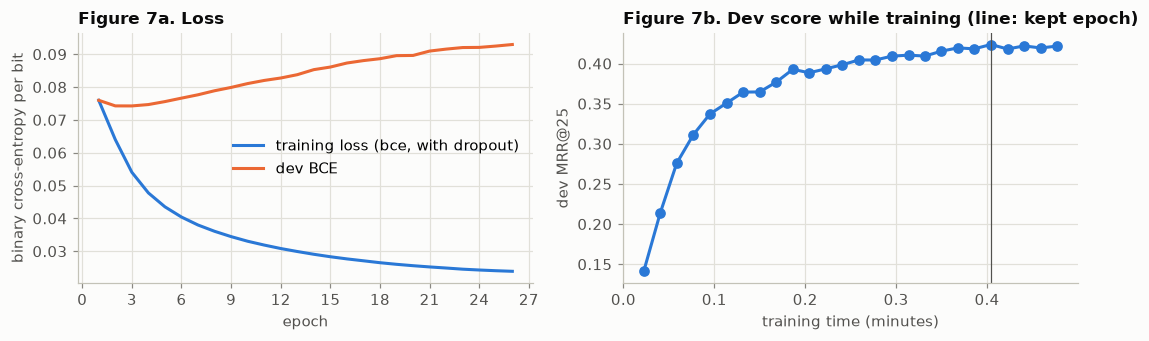

112,757 spectra of 13,470 molecules; 19.6M parameters (4.2M outside the input layer); 102,381 spectra/s on NVIDIA GeForce RTX 4080


In [22]:
base = run("base", BASE, keep_model=True)
h = base.history
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.2))
left.plot(h["epoch"], h["train_loss"], color=BLUE, label=f"training loss ({BASE.loss}, with dropout)")
left.plot(h["epoch"], h["dev_bce"], color=ORANGE, label="dev BCE")
left.set_xlabel("epoch")
left.set_ylabel("binary cross-entropy per bit")
left.set_title("Figure 7a. Loss")
left.legend()
integer_ticks(left)
right.plot(np.cumsum(h["seconds"]) / 60, h["dev_mrr"], marker="o", color=BLUE)
right.axvline(np.cumsum(h["seconds"])[base.summary["train"]["best_epoch"] - 1] / 60, color=INK_SOFT, linewidth=0.8)
right.set_xlabel("training time (minutes)")
right.set_ylabel("dev MRR@25")
right.set_title("Figure 7b. Dev score while training (line: kept epoch)")
plt.tight_layout()
plt.show()
t = base.summary["train"]
print(f"{t['spectra']:,} spectra of {t['molecules']:,} molecules; {t['params'] / 1e6:.1f}M parameters "
      f"({t['dense_params'] / 1e6:.1f}M outside the input layer); {t['spectra_per_second']:,.0f} spectra/s on {base.summary['device']}")

Dev BCE and dev MRR need not move together: BCE also punishes over-confident bits, MRR only the
order of the candidates. Early stopping watches MRR, the quantity the benchmark scores. The gap
between the training and dev curves shows how much the network memorises its training molecules.

### 6.2 Results

In [23]:
RESULTS = {"random order": summarise(BASELINES["random order"]), "nearest mass": summarise(BASELINES["nearest mass"]),
           "fingerprint MLP": base.summary["val"],
           "oracle fingerprint (ceiling)": summarise(ORACLE[(FP_RADIUS, FP_BITS)])}
show(summary_table(RESULTS).sort("group", maintain_order=True))
print(f"class 3, similarity of the top guess to the answer (Tanimoto): MLP {base.summary['val']['class 3']['top1_tanimoto']:.3f}, "
      f"nearest mass {RESULTS['nearest mass']['class 3']['top1_tanimoto']:.3f}, random {RESULTS['random order']['class 3']['top1_tanimoto']:.3f}")

method,group,molecules,MRR@25,95% CI,hit@1,hit@5,hit@25
str,str,i64,f64,str,f64,f64,f64
"""random order""","""class 1""",1038,0.110,"""0.102 to 0.118""",0.040,0.167,0.493
"""nearest mass""","""class 1""",1038,0.175,"""0.162 to 0.189""",0.076,0.274,0.626
"""fingerprint MLP""","""class 1""",1038,0.411,"""0.387 to 0.436""",0.280,0.566,0.836
"""oracle fingerprint (ceiling)""","""class 1""",1038,1.000,"""0.999 to 1.000""",0.999,1.000,1.000
"""random order""","""class 2""",961,0.085,"""0.078 to 0.091""",0.028,0.122,0.438
"""nearest mass""","""class 2""",961,0.143,"""0.131 to 0.156""",0.056,0.215,0.599
"""fingerprint MLP""","""class 2""",961,0.404,"""0.378 to 0.430""",0.284,0.536,0.806
"""oracle fingerprint (ceiling)""","""class 2""",961,1.000,"""1.000 to 1.000""",1.000,1.000,1.000
"""random order""","""classes 1+2""",1999,0.098,"""0.093 to 0.103""",0.034,0.145,0.467


class 3, similarity of the top guess to the answer (Tanimoto): MLP nan, nearest mass nan, random nan


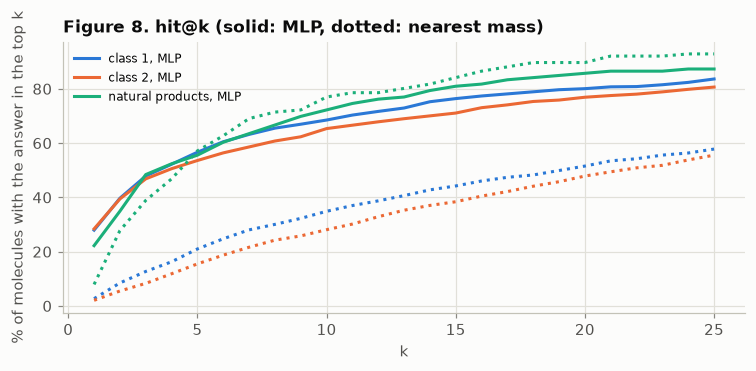

In [24]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ks = np.arange(1, TOP_K + 1)
for name, cond in [("class 1", pl.col("sim_class") == 1), ("class 2", pl.col("sim_class") == 2), ("natural products", pl.col("pool") == NP)]:
    for method, frame, style in [("MLP", base.val, "-"), ("nearest mass", BASELINES["nearest mass"], ":")]:
        ranks = frame.filter(cond)["rank"].fill_nan(1e9).fill_null(1e9).to_numpy()
        if len(ranks):
            ax.plot(ks, [(ranks <= k).mean() * 100 for k in ks], style, color=GROUP_COLOURS[name],
                    label=f"{name}, {method}" if method == "MLP" else None)
ax.set_xlabel("k")
ax.set_ylabel("% of molecules with the answer in the top k")
ax.set_title("Figure 8. hit@k (solid: MLP, dotted: nearest mass)")
ax.legend(fontsize=8)
plt.show()

### 6.3 What the network learned

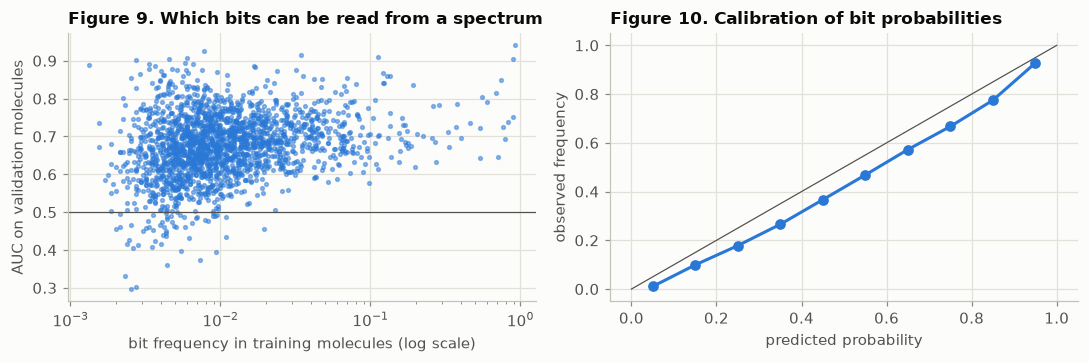

median per-bit AUC 0.678; bits with AUC > 0.9: 8 of 1992 testable; expected calibration error 0.0403


In [25]:
# Molecule-level predictions on validation: per-bit AUC (can the bit be read from a spectrum?) and calibration.
val_logits = predict(base.model, VAL.spectra, BASE)
p_val = np.vstack([sigmoid(val_logits[VAL.offsets[q]:VAL.offsets[q + 1]]).mean(0) for q in range(VAL.n)])
y_val = np.unpackbits(FP[VAL.table["mol"].to_numpy()], axis=1).astype(bool)


def per_bit_auc(scores: np.ndarray, labels: np.ndarray) -> np.ndarray:
    # Mann-Whitney AUC for every column at once; NaN where a bit is always or never set.
    ranks = scores.argsort(0).argsort(0) + 1
    n_pos = labels.sum(0)
    n_neg = len(labels) - n_pos
    auc = ((ranks * labels).sum(0) - n_pos * (n_pos + 1) / 2) / np.maximum(n_pos * n_neg, 1)
    return np.where((n_pos > 4) & (n_neg > 4), auc, np.nan)


auc = per_bit_auc(p_val, y_val)
train_freq = bit_frequency(molecules.filter(~pl.col("is_dev") & (pl.col("train_subset_rank") < BASE.fraction)
                                            & (pl.col("n_train_spectra") > 0))["mol"].to_numpy())
edges = np.linspace(0, 1, 11)
centres = (edges[:-1] + edges[1:]) / 2
which = np.clip(np.digitize(p_val.ravel(), edges) - 1, 0, 9)
observed = np.array([y_val.ravel()[which == b].mean() if (which == b).any() else np.nan for b in range(10)])
counts = np.bincount(which, minlength=10)

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.4))
ok = ~np.isnan(auc)
left.scatter(np.maximum(train_freq[ok], 1e-5), auc[ok], s=6, color=BLUE, alpha=0.5)
left.set_xscale("log")
left.axhline(0.5, color=INK_SOFT, linewidth=0.8)
left.set_xlabel("bit frequency in training molecules (log scale)")
left.set_ylabel("AUC on validation molecules")
left.set_title("Figure 9. Which bits can be read from a spectrum")
right.plot([0, 1], [0, 1], color=INK_SOFT, linewidth=0.8)
right.plot(centres, observed, marker="o", color=BLUE)
right.set_xlabel("predicted probability")
right.set_ylabel("observed frequency")
right.set_title("Figure 10. Calibration of bit probabilities")
plt.tight_layout()
plt.show()
ece = np.nansum(counts / counts.sum() * np.abs(observed - centres))
print(f"median per-bit AUC {np.nanmedian(auc):.3f}; bits with AUC > 0.9: {(auc > 0.9).sum()} of {ok.sum()} testable; "
      f"expected calibration error {ece:.4f}")

Figure 9 shows which substructures the spectrum reveals; figure 10 checks the assumption behind
the log-likelihood score (section 7.2). A curve below the diagonal means overconfident bits.

### 6.4 One example, and where it fails

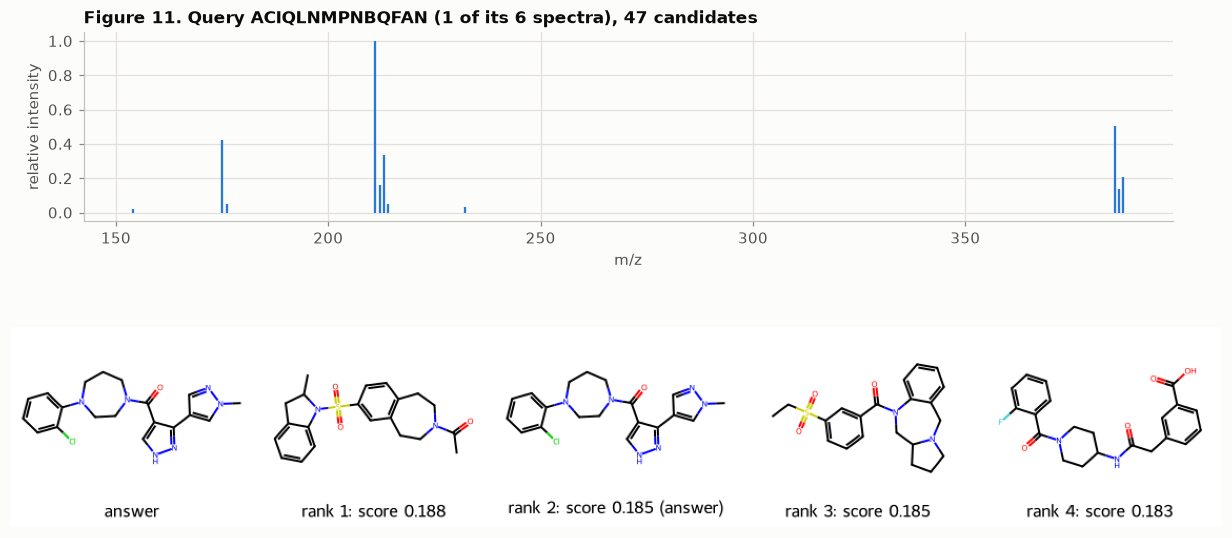

In [26]:
# A class 2 molecule the model ranks well but not first: the answer and the candidates above it.
_, tops = rank_queries(VAL, model_score(VAL, val_logits), keep_top=4)
pick = (base.val.with_row_index("q").filter((pl.col("sim_class") == 2) & (pl.col("rank") > 1) & (pl.col("rank") <= 4)))
pick = pick if pick.height else base.val.with_row_index("q").filter(pl.col("truth_in_set"))
q = int(pick["q"][0])
mol = int(VAL.table["mol"][q])
shown = tops.filter(pl.col("mol") == mol)
smiles = molecules["smiles"].to_list()
images = [Chem.MolFromSmiles(smiles[m]) or Chem.Mol() for m in [mol, *shown["candidate_mol"].to_list()]]
legends = ["answer"] + [f"rank {r}: score {s:.3f}" + (" (answer)" if int(c) == mol else "")
                        for r, s, c in zip(shown["rank"], shown["score"], shown["candidate_mol"])]
grid = Draw.MolsToGridImage(images, molsPerRow=len(images), subImgSize=(230, 190), legends=legends)

fig = plt.figure(figsize=(11, 5.2))
ax = fig.add_axes([0.06, 0.62, 0.9, 0.33])
peaks = slice(VAL.spectra.offsets[VAL.offsets[q]], VAL.spectra.offsets[VAL.offsets[q] + 1])
ax.vlines(VAL.spectra.mz[peaks], 0, VAL.spectra.intensity[peaks], color=BLUE, linewidth=1.5)
ax.set_xlabel("m/z")
ax.set_ylabel("relative intensity")
n_spectra = VAL.table["n_spectra"][q]
ax.set_title(f"Figure 11. Query {VAL.table['inchikey14'][q]} ({'its only spectrum' if n_spectra == 1 else f'1 of its {n_spectra} spectra'}), "
             f"{base.val['n_candidates'][q]} candidates")
image_ax = fig.add_axes([0.0, 0.0, 1.0, 0.52])
image_ax.imshow(grid)
image_ax.axis("off")
plt.show()

In [27]:
# Where it fails: MRR by number of candidates, precursor mass and number of query spectra (classes 1 and 2).
answerable_val = base.val.join(VAL.table.select("inchikey14", "mass"), on="inchikey14").filter(pl.col("sim_class").is_in([1, 2]))
cuts = {"candidates": ("n_candidates", [0, 5, 25, 100, 1000, 10**9]), "neutral mass (Da)": ("mass", [0, 250, 350, 450, 600, 10**9]),
        "query spectra": ("n_spectra", [0, 1, 2, 4, 8, 10**9])}
tables = []
for label, (column, bins) in cuts.items():
    integer = column != "mass"
    names = [f">{a}" if b >= 10**9 else (str(b) if integer and a + 1 == b else f"{a + integer}-{b}") for a, b in zip(bins[:-1], bins[1:])]
    bucket = np.digitize(answerable_val[column].to_numpy(), bins[1:-1], right=True)
    tables.append(answerable_val.with_columns(pl.Series("b", bucket)).group_by("b")
                  .agg(pl.len().alias("molecules"), pl.col("rr").mean().alias("MRR@25")).sort("b")
                  .with_columns(pl.lit(label).alias("by"), pl.col("b").map_elements(lambda i: names[i], return_dtype=pl.String).alias("bucket"))
                  .select("by", "bucket", "molecules", "MRR@25"))
show(pl.concat(tables))

by,bucket,molecules,MRR@25
str,str,u32,f64
"""candidates""","""1-5""",58,0.786
"""candidates""","""6-25""",308,0.540
"""candidates""","""26-100""",906,0.401
"""candidates""","""101-1000""",727,0.330
"""neutral mass (Da)""","""0-250""",46,0.471
"""neutral mass (Da)""","""250-350""",1434,0.380
"""neutral mass (Da)""","""350-450""",493,0.470
"""neutral mass (Da)""","""450-600""",14,0.645
"""neutral mass (Da)""",""">600""",12,0.736


## 7. Ablations

### 7.1 One change at a time

Each run changes one setting from the base run and trains from scratch on the same subset with the
same seed. Differences are paired over the same validation molecules; the base run repeated with
other seeds shows how much a difference can come from the random seed alone.

In [28]:
ABLATIONS = [
    ("loss", "weighted BCE", dict(loss="wbce")),
    ("loss", "focal loss", dict(loss="focal")),
    ("loss", "soft Tanimoto loss", dict(loss="tanimoto")),
    ("loss", "BCE + 0.1 Tanimoto", dict(loss="bce+tanimoto")),
    ("input", "1 Da bins", dict(bin_width=1.0)),
    ("input", "0.01 Da bins (SparseAdam)", dict(bin_width=0.01, sparse_grad=True)),
    ("input", "raw intensity", dict(intensity="raw")),
    ("input", "log intensity", dict(intensity="log")),
    ("input", "peak presence only", dict(intensity="binary")),
    ("input", "+ neutral losses", dict(neutral_losses=True)),
    ("input", "no metadata", dict(metadata=False)),
    ("optimiser", "SparseAdam for the input layer", dict(sparse_grad=True)),
    ("model", "no dropout", dict(dropout=0.0)),
    ("model", "dropout 0.5", dict(dropout=0.5)),
    ("model", "depth 2 (one hidden block)", dict(depth=2)),
    ("model", "depth 5 (four hidden blocks)", dict(depth=5)),
    ("data", "timsTOF spectra only", dict(instruments="timsTOF")),
    ("data", "other instruments only", dict(instruments="other")),
    ("data", "one spectrum per molecule", dict(one_per_molecule=True)),
    ("data", "molecules with 5+ spectra only", dict(min_spectra=5)),
    ("data", "no dimer spectra", dict(drop_dimers=True)),
    ("data", "tallest 20 peaks", dict(top_peaks=20)),
    ("data", "tallest 10 peaks", dict(top_peaks=10)),
    ("data", "tallest 5 peaks", dict(top_peaks=5)),
]
ABLATION_RUNS = {label: run(label, replace(BASE, **change)) for _, label, change in ABLATIONS}
SEED_RUNS = {s: (base if s == BASE.seed else run(f"base seed {s}", replace(BASE, seed=s))) for s in PLAN["seeds"]}

base: dev MRR 0.424, val MRR (classes 1+2) 0.408; standard deviation over seeds [0, 1, 2]: 0.005


group,change,dev MRR,"val MRR, classes 1+2",Δ vs base,Δ 95% CI,Δ class 2,Δ NP,epochs,s/epoch,verdict
str,str,f64,f64,f64,str,f64,f64,i64,f64,str
"""loss""","""weighted BCE""",0.454,0.443,0.036,"""+0.023 to +0.048""",0.047,0.014,16,1.101,"""helps"""
"""loss""","""focal loss""",0.390,0.367,-0.041,"""-0.054 to -0.028""",-0.035,-0.010,28,1.103,"""hurts"""
"""loss""","""soft Tanimoto loss""",0.230,0.242,-0.166,"""-0.182 to -0.150""",-0.178,-0.040,27,1.165,"""hurts"""
"""loss""","""BCE + 0.1 Tanimoto""",0.394,0.387,-0.021,"""-0.031 to -0.009""",-0.024,0.014,24,1.179,"""hurts"""
"""input""","""1 Da bins""",0.381,0.374,-0.034,"""-0.047 to -0.020""",-0.031,-0.016,30,0.568,"""hurts"""
"""input""","""0.01 Da bins (SparseAdam)""",0.533,0.520,0.112,"""+0.096 to +0.127""",0.117,0.064,15,0.796,"""helps"""
"""input""","""raw intensity""",0.355,0.346,-0.062,"""-0.074 to -0.051""",-0.066,-0.014,30,1.076,"""hurts"""
"""input""","""log intensity""",0.429,0.412,0.004,"""-0.006 to +0.014""",0.002,-0.023,24,1.057,"""unclear"""
"""input""","""peak presence only""",0.371,0.363,-0.045,"""-0.059 to -0.031""",-0.044,-0.016,20,1.034,"""hurts"""


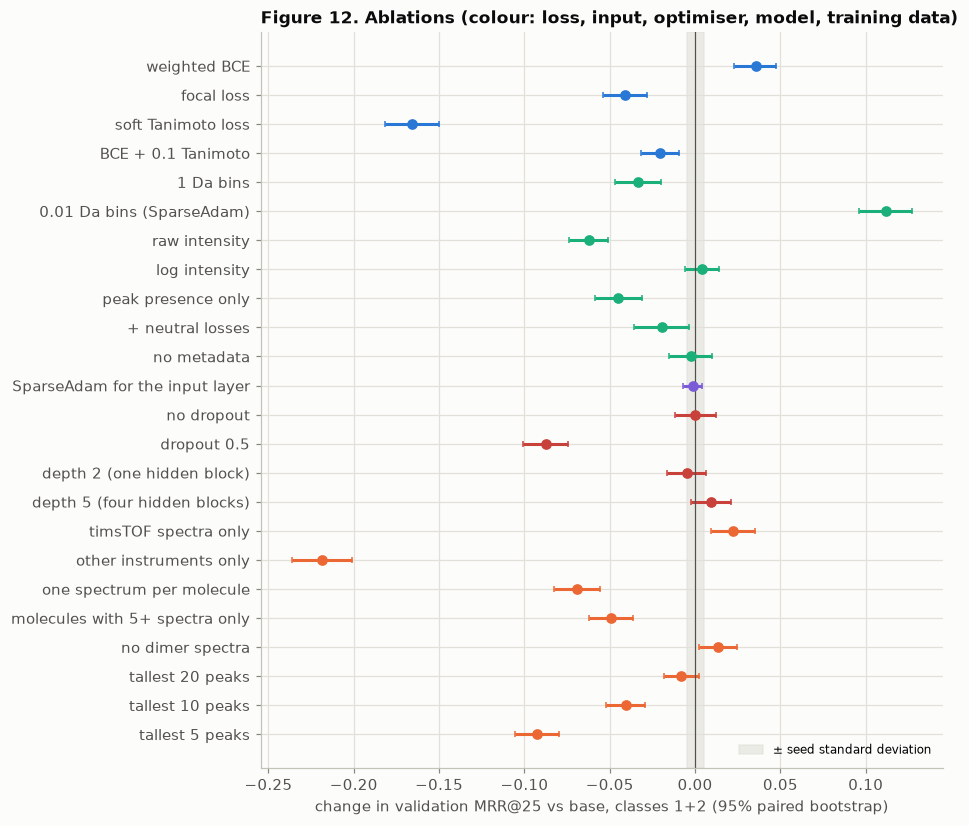

In [29]:
seed_spread = np.std([r.mrr() for r in SEED_RUNS.values()], ddof=1) if len(SEED_RUNS) > 1 else math.nan
rows, deltas = [], []
for group, label, _ in ABLATIONS:
    r = ABLATION_RUNS[label]
    d, low, high = paired_delta(base, r)
    deltas.append((group, label, d, low, high))
    d2, low2, high2 = paired_delta(base, r, "class 2")
    rows.append({"group": group, "change": label, "dev MRR": r.summary["dev"]["mrr"], "val MRR, classes 1+2": r.mrr(),
                 "Δ vs base": d, "Δ 95% CI": f"{low:+.3f} to {high:+.3f}", "Δ class 2": d2, "Δ NP": paired_delta(base, r, "natural products")[0],
                 "epochs": r.summary["train"]["epochs"], "s/epoch": r.summary["train"]["seconds_per_epoch"],
                 "verdict": "helps" if low > 0 else "hurts" if high < 0 else "unclear"})
ABLATION_TABLE = pl.DataFrame(rows)
print(f"base: dev MRR {base.summary['dev']['mrr']:.3f}, val MRR (classes 1+2) {base.mrr():.3f}; "
      f"standard deviation over seeds {PLAN['seeds']}: {seed_spread:.3f}")
show(ABLATION_TABLE)

fig, ax = plt.subplots(figsize=(8, 0.32 * len(rows) + 1))
colours = {"loss": BLUE, "input": AQUA, "optimiser": PURPLE, "model": RED, "data": ORANGE}
for i, (group, label, d, low, high) in enumerate(deltas):
    ax.errorbar(d, i, xerr=[[d - low], [high - d]], fmt="o", color=colours[group], capsize=2)
ax.axvline(0, color=INK_SOFT, linewidth=0.8)
if not math.isnan(seed_spread):
    ax.axvspan(-seed_spread, seed_spread, color=GRID, alpha=0.6, label="± seed standard deviation")
    ax.legend(fontsize=8, loc="lower right")
ax.set_yticks(range(len(rows)), [label for _, label, _ in ABLATIONS])
ax.invert_yaxis()
ax.set_xlabel("change in validation MRR@25 vs base, classes 1+2 (95% paired bootstrap)")
ax.set_title("Figure 12. Ablations (colour: loss, input, optimiser, model, training data)")
plt.show()

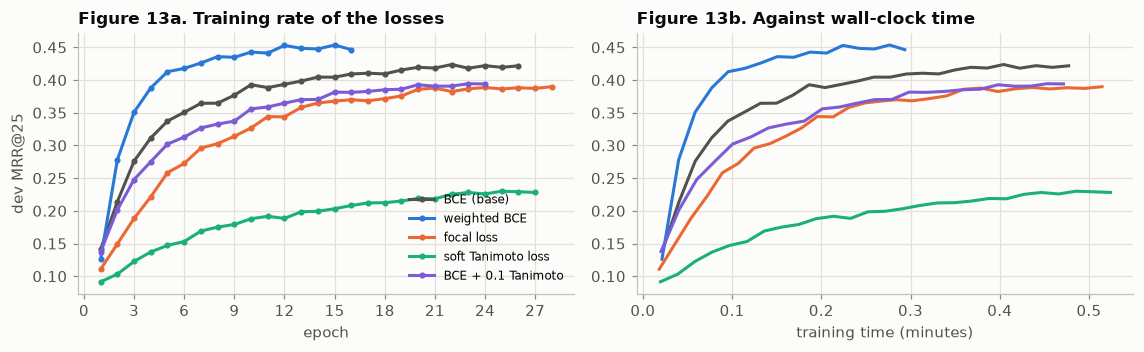

loss,best dev MRR,best epoch,minutes to best,s per epoch
str,f64,i64,f64,f64
"""BCE (base)""",0.424,22,0.404,1.101
"""weighted BCE""",0.454,15,0.276,1.101
"""focal loss""",0.390,28,0.515,1.103
"""soft Tanimoto loss""",0.230,25,0.485,1.165
"""BCE + 0.1 Tanimoto""",0.394,23,0.453,1.179


In [30]:
# Training rate: how fast each loss reaches its best dev score.
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 3.3))
loss_runs = [("BCE (base)", base)] + [(label, ABLATION_RUNS[label]) for group, label, _ in ABLATIONS if group == "loss"]
for (label, r), colour in zip(loss_runs, [INK_SOFT, BLUE, ORANGE, AQUA, PURPLE]):
    h = r.history
    left.plot(h["epoch"], h["dev_mrr"], marker="o", markersize=3, color=colour, label=label)
    right.plot(np.cumsum(h["seconds"].to_numpy()) / 60, h["dev_mrr"], color=colour)
left.set_xlabel("epoch")
left.set_ylabel("dev MRR@25")
left.set_title("Figure 13a. Training rate of the losses")
left.legend(fontsize=8)
integer_ticks(left)
right.set_xlabel("training time (minutes)")
right.set_title("Figure 13b. Against wall-clock time")
plt.tight_layout()
plt.show()
show(pl.DataFrame([{"loss": label, "best dev MRR": r.summary["dev"]["mrr"], "best epoch": r.summary["train"]["best_epoch"],
                    "minutes to best": r.summary["train"]["seconds_to_best"] / 60, "s per epoch": r.summary["train"]["seconds_per_epoch"]}
                   for label, r in loss_runs]))

How to read the data rows: *timsTOF only* and *other instruments only* split the training set by
instrument, so the gap between them is the value of same-instrument data; *one spectrum per
molecule* keeps the molecules but drops most of the spectra, while *5+ spectra only* keeps the
spectra of well-measured molecules and drops the rest (the minimum the protocol does not use); the
peak limits show how much of the answer is in the small peaks.

### 7.2 Scoring and aggregation without retraining

The scoring rule and the way a molecule's spectra are combined are applied after training, so all
nine combinations come from the same base model. Dev picks the default; val confirms.

In [31]:
dev_logits = predict(base.model, DEV.spectra, BASE)
rows = []
for scoring in ["tanimoto", "cosine", "loglik"]:
    for aggregate in ["mean_prob", "mean_logit", "max"]:
        dev_rr = rank_queries(DEV, model_score(DEV, dev_logits, scoring, aggregate))["rr"].mean()
        val_res = rank_queries(VAL, model_score(VAL, val_logits, scoring, aggregate))
        s = summarise(val_res)
        rows.append({"scoring": scoring, "aggregate": aggregate, "dev MRR": dev_rr, "val MRR, classes 1+2": s["classes 1+2"]["mrr"],
                     "val class 2": s["class 2"]["mrr"], "val natural products": s["natural products"]["mrr"]})
SCORING_TABLE = pl.DataFrame(rows).sort("dev MRR", descending=True)
show(SCORING_TABLE)
BEST_SCORING = SCORING_TABLE.row(0, named=True)

scoring,aggregate,dev MRR,"val MRR, classes 1+2",val class 2,val natural products
str,str,f64,f64,f64,f64
"""tanimoto""","""mean_prob""",0.424,0.408,0.404,0.382
"""cosine""","""mean_prob""",0.423,0.409,0.405,0.390
"""cosine""","""max""",0.421,0.416,0.420,0.398
"""tanimoto""","""max""",0.414,0.408,0.411,0.393
"""cosine""","""mean_logit""",0.393,0.372,0.372,0.354
"""tanimoto""","""mean_logit""",0.390,0.373,0.371,0.358
"""loglik""","""max""",0.368,0.380,0.382,0.374
"""loglik""","""mean_prob""",0.360,0.375,0.374,0.379
"""loglik""","""mean_logit""",0.340,0.353,0.344,0.374


### 7.3 Window width, without retraining

In [32]:
rows = []
for ppm in [2, 5, 10, 20, 50]:
    res = rank_queries(VAL, model_score(VAL, val_logits), ppm=ppm)
    answer = res.filter(pl.col("sim_class").is_in([1, 2]))
    rows.append({"ppm": ppm, "median candidates": answer["n_candidates"].median(), "answer in window": answer["truth_in_set"].mean(),
                 "MRR@25, classes 1+2": answer["rr"].mean()})
show(pl.DataFrame(rows))

ppm,median candidates,answer in window,"MRR@25, classes 1+2"
i64,f64,f64,f64
2,8.000,0.528,0.260
5,47.000,0.998,0.441
10,71.000,1.000,0.408
20,112.000,1.000,0.372
50,279.000,1.000,0.302


### 7.4 One part file, or a random sample of the same size?

The first part file as the whole training set, against a protocol subset holding about as many
spectra. Same model, same seed, so a gap comes from which spectra they are, not how many.

In [33]:
n_part = int((LIBRARIES["part"] == 0).sum())
F_MATCH = round(n_part / LIBRARIES.height, 4)          # the fraction of molecules that gives about as many spectra
PART_RUN = run("part 000 only", replace(BASE, fraction=1.0, part=0))
MATCHED_RUN = run(f"random {F_MATCH:.1%} subset", replace(BASE, fraction=F_MATCH))
rows = []
for label, r, frame in [("part 000 only", PART_RUN, LIBRARIES.filter(pl.col("part") == 0)),
                        (f"protocol subset, {F_MATCH:.1%} of molecules", MATCHED_RUN, LIBRARIES.filter(pl.col("train_subset_rank") < F_MATCH))]:
    shares = library_mix(frame)
    largest = max(shares, key=shares.get)
    rows.append({"training set": label, "spectra": r.summary["train"]["spectra"], "molecules": r.summary["train"]["molecules"],
                 "largest library": f"{largest} ({shares[largest]:.0%})", "dev MRR": r.summary["dev"]["mrr"],
                 "val class 1": r.mrr("class 1"), "val class 2": r.mrr("class 2"),
                 "val natural products": r.mrr("natural products"), "val classes 1+2": r.mrr()})
show(pl.DataFrame(rows))
for group in ["classes 1+2", "class 1", "class 2", "natural products"]:
    d, low, high = paired_delta(PART_RUN, MATCHED_RUN, group)
    print(f"{group:>17}: protocol subset minus part 000 = {d:+.3f} (95% CI {low:+.3f} to {high:+.3f})")

training set,spectra,molecules,largest library,dev MRR,val class 1,val class 2,val natural products,val classes 1+2
str,i64,i64,str,f64,f64,f64,f64,f64
"""part 000 only""",125499,22041,"""enveda-180 (98%)""",0.566,0.519,0.522,0.363,0.520
"""protocol subset, 5.5% of molecules""",123958,14814,"""enveda-180 (49%)""",0.432,0.431,0.416,0.379,0.424


      classes 1+2: protocol subset minus part 000 = -0.096 (95% CI -0.113 to -0.078)
          class 1: protocol subset minus part 000 = -0.088 (95% CI -0.111 to -0.064)
          class 2: protocol subset minus part 000 = -0.105 (95% CI -0.129 to -0.081)
 natural products: protocol subset minus part 000 = +0.016 (95% CI -0.043 to +0.071)


## 8. Scaling with data volume

The base model on each nested subset of the protocol, 1% to 100%. Models are fitted and tuned at 5%;
10% is the first check of how the score grows, and section 8.1 forecasts the larger runs from the
runs up to 10% before comparing with what they scored. Smaller subsets also get extra seeds, since
their scores move most with the seed. A second series keeps one spectrum per molecule, to separate
*more molecules* from *more spectra of the same molecules*.

In [34]:
SCALE = {f: run(f"scale {f}", replace(BASE, fraction=f)) for f in PLAN["scaling_fractions"]}
SCALE_SEEDS = {(f, s): run(f"scale {f} seed {s}", replace(BASE, fraction=f, seed=s))
               for f in PLAN["scaling_fractions"] if f <= BASE.fraction for s in PLAN["seeds"] if s != BASE.seed}
SCALE_ONE = {f: run(f"scale {f}, one spectrum per molecule", replace(BASE, fraction=f, one_per_molecule=True))
             for f in PLAN["scaling_fractions"]}

rows = []
for f, r in SCALE.items():
    t, v = r.summary["train"], r.summary["val"]
    seeds = [r.mrr()] + [SCALE_SEEDS[(f, s)].mrr() for s in PLAN["seeds"] if (f, s) in SCALE_SEEDS]
    rows.append({"fraction": f, "molecules": t["molecules"], "spectra": t["spectra"], "MRR class 1": v["class 1"]["mrr"],
                 "MRR class 2": v["class 2"]["mrr"], "MRR natural products": v["natural products"]["mrr"],
                 "MRR 1+2": v["classes 1+2"]["mrr"], "seed sd": np.std(seeds, ddof=1) if len(seeds) > 1 else None,
                 "seen MRR": r.summary["seen"]["mrr"], "dev BCE": r.summary["dev"]["bce"], "epochs": t["epochs"],
                 "best epoch": t["best_epoch"], "minutes": t["seconds"] / 60})
SCALE_TABLE = pl.DataFrame(rows)
show(SCALE_TABLE)

fraction,molecules,spectra,MRR class 1,MRR class 2,MRR natural products,MRR 1+2,seed sd,seen MRR,dev BCE,epochs,best epoch,minutes
f64,i64,i64,f64,f64,f64,f64,f64,f64,f64,i64,i64,f64
0.010,2673,21628,0.279,0.287,0.330,0.283,0.007,1.000,0.109,12,12,0.043
0.050,13470,112757,0.411,0.404,0.382,0.408,0.005,0.986,0.092,26,22,0.477
0.100,27101,227223,0.462,0.445,0.457,0.454,null,0.865,0.077,28,26,0.994
0.250,67620,570495,0.525,0.505,0.486,0.516,null,0.705,0.070,24,24,2.145
0.500,134831,1138813,0.575,0.571,0.512,0.573,null,0.662,0.067,27,23,4.832
1.000,270197,2289876,0.647,0.616,0.728,0.632,null,0.662,0.065,21,17,7.535


### 8.1 Power laws

Error falling as a power of the data size, approaching a floor, is the usual empirical law for
neural networks (Hestness et al., 2017; Kaplan et al., 2020):

$$\varepsilon(D) = c + a\,D^{-\alpha},$$

with $D$ the number of training molecules and $\varepsilon = 1 -$ MRR (or the dev BCE). The fit is a
grid over the floor $c$ with a straight line in log space for each, so no extra library is needed.
Three checks on how far it can be trusted: forecast the larger subsets from the runs up to 10%
(with fewer than four points the floor $c$ is fixed at 0), refit with only the largest subset left
out and predict it, and refit on bootstrap resamples of the validation molecules.

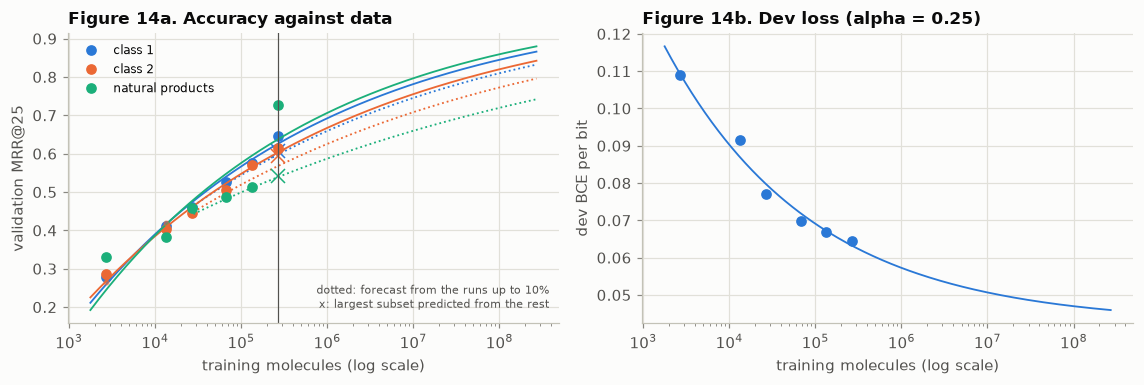

group,alpha,alpha 95% CI,floor (best possible MRR = 1 - c),largest subset: observed,forecast from runs up to 10%,predicted from all the others,extrapolated to 1000x,1000x 95% CI
str,f64,str,f64,f64,f64,f64,f64,str
"""class 1""",0.149,"""0.14 to 0.16""",1.000,0.647,0.598,0.608,0.866,"""0.847 to 0.886"""
"""class 2""",0.133,"""0.12 to 0.15""",1.000,0.616,0.568,0.593,0.842,"""0.817 to 0.863"""
"""natural products""",0.160,"""0.13 to 0.20""",1.000,0.728,0.539,0.541,0.880,"""0.825 to 0.924"""


In [35]:
def fit_power_law(x: np.ndarray, y: np.ndarray):
    # Least-squares fit of y = c + a x^-alpha over a grid of floors c. Returns (c, a, alpha).
    best = (math.inf, None)
    for c in np.linspace(0, 0.995 * y.min(), 400):
        slope, intercept = np.polyfit(np.log(x), np.log(y - c), 1)
        error = ((c + np.exp(intercept) * x ** slope - y) ** 2).sum()
        if error < best[0]:
            best = (error, (c, float(np.exp(intercept)), float(-slope)))
    return best[1]


def law(x, params):
    c, a, alpha = params
    return c + a * np.asarray(x, dtype=float) ** -alpha


def fit_law(x: np.ndarray, y: np.ndarray):
    # The full law with four or more points; a pure power law (c = 0) with two or three.
    if len(x) >= 4:
        return fit_power_law(x, y)
    slope, intercept = np.polyfit(np.log(x), np.log(y), 1)
    return 0.0, float(np.exp(intercept)), float(-slope)


fractions = sorted(SCALE)
D = np.array([SCALE[f].summary["train"]["molecules"] for f in fractions], dtype=float)
FITS = {}
if len(fractions) >= 3:
    fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 3.6))
    grid_x = np.logspace(np.log10(D.min() / 1.5), np.log10(D.max() * 1000), 200)
    for group in ["class 1", "class 2", "natural products"]:
        err = np.array([1 - SCALE[f].mrr(group) for f in fractions])
        if np.isnan(err).any():
            continue
        params = fit_power_law(D, err)
        loo = fit_power_law(D[:-1], err[:-1]) if len(D) >= 4 else None
        early = [i for i, f in enumerate(fractions) if f <= 0.1]
        forecast = fit_law(D[early], err[early]) if 2 <= len(early) < len(fractions) else None
        boots = []
        for b in range(200):     # resample validation molecules, refit
            rng = np.random.default_rng(b)
            ids = SCALE[fractions[0]].val.filter(EVAL_GROUPS[group])["inchikey14"]
            sample = pl.DataFrame({"inchikey14": ids.to_numpy()[rng.integers(0, len(ids), len(ids))]})
            e = np.array([1 - sample.join(SCALE[f].val.select("inchikey14", "rr"), on="inchikey14")["rr"].mean() for f in fractions])
            boots.append(fit_power_law(D, e))
        FITS[group] = {"params": params, "loo": loo, "forecast": forecast, "boots": boots, "err": err}
        colour = GROUP_COLOURS[group]
        left.plot(D, 1 - err, "o", color=colour, label=group)
        left.plot(grid_x, 1 - law(grid_x, params), color=colour, linewidth=1.2)
        if loo:
            left.plot(D[-1], 1 - law(D[-1], loo), "x", color=colour, markersize=9)
        if forecast:
            later = grid_x >= D[early[-1]]
            left.plot(grid_x[later], 1 - law(grid_x[later], forecast), ":", color=colour, linewidth=1.2)
    for (f, s), r in SCALE_SEEDS.items():
        left.plot(r.summary["train"]["molecules"], r.mrr("class 2"), ".", color=ORANGE, alpha=0.5)
    left.axvline(D.max(), color=INK_SOFT, linewidth=0.8)
    left.set_xscale("log")
    left.set_xlabel("training molecules (log scale)")
    left.text(0.98, 0.04, "dotted: forecast from the runs up to 10%\nx: largest subset predicted from the rest",
              transform=left.transAxes, ha="right", va="bottom", fontsize=7.5, color=INK_SOFT)
    left.set_ylabel("validation MRR@25")
    left.set_title("Figure 14a. Accuracy against data")
    left.legend(fontsize=8)
    bce = np.array([SCALE[f].summary["dev"]["bce"] for f in fractions])
    bce_fit = fit_power_law(D, bce)
    FITS["dev BCE"] = {"params": bce_fit}
    right.plot(D, bce, "o", color=BLUE)
    right.plot(grid_x, law(grid_x, bce_fit), color=BLUE, linewidth=1.2)
    right.set_xscale("log")
    right.set_xlabel("training molecules (log scale)")
    right.set_ylabel("dev BCE per bit")
    right.set_title(f"Figure 14b. Dev loss (alpha = {bce_fit[2]:.2f})")
    plt.tight_layout()
    plt.show()

    rows = []
    for group, result in FITS.items():
        if group == "dev BCE":
            continue
        c, a, alpha = result["params"]
        alphas = [b[2] for b in result["boots"]]
        at_1000 = [1 - law(D.max() * 1000, b) for b in result["boots"]]
        rows.append({"group": group, "alpha": alpha, "alpha 95% CI": f"{np.percentile(alphas, 2.5):.2f} to {np.percentile(alphas, 97.5):.2f}",
                     "floor (best possible MRR = 1 - c)": 1 - c,
                     "largest subset: observed": 1 - result["err"][-1],
                     "forecast from runs up to 10%": 1 - law(D[-1], result["forecast"]) if result["forecast"] else None,
                     "predicted from all the others": 1 - law(D[-1], result["loo"]) if result["loo"] else None,
                     "extrapolated to 1000x": 1 - law(D.max() * 1000, result["params"]),
                     "1000x 95% CI": f"{np.percentile(at_1000, 2.5):.3f} to {np.percentile(at_1000, 97.5):.3f}"})
    show(pl.DataFrame(rows))
else:
    print("needs at least three training subsets: run with RUN_SIZE = 'quick' or 'full'")

The forecast from the runs up to 10% is what we would have predicted for 100% before training on
it; its error is the honest measure of how well small runs predict large ones. Extrapolating three
orders of magnitude past the data is the weakest claim here: the bootstrap interval covers only noise
in the validation set, not a change in the law (a floor reached earlier, or a different regime).

### 8.2 Training rate

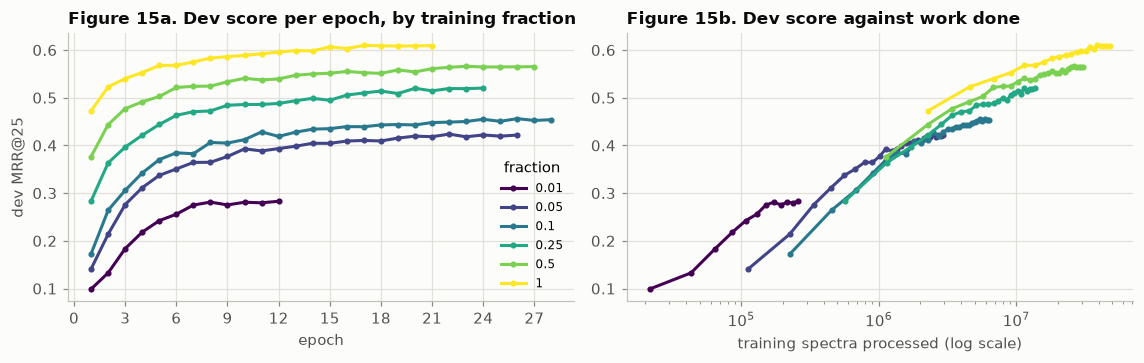

In [36]:
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 3.4))
cmap = plt.get_cmap("viridis")
for i, f in enumerate(fractions):
    h = SCALE[f].history
    colour = cmap(i / max(len(fractions) - 1, 1))
    left.plot(h["epoch"], h["dev_mrr"], marker="o", markersize=3, color=colour, label=f"{f:g}")
    right.plot(h["spectra_seen"], h["dev_mrr"], marker="o", markersize=3, color=colour)
left.set_xlabel("epoch")
left.set_ylabel("dev MRR@25")
left.set_title("Figure 15a. Dev score per epoch, by training fraction")
left.legend(title="fraction", fontsize=8)
integer_ticks(left)
right.set_xscale("log")
right.set_xlabel("training spectra processed (log scale)")
right.set_title("Figure 15b. Dev score against work done")
plt.tight_layout()
plt.show()

Figure 15b puts the subsets on one axis of work: if the curves lie on top of each other, extra
data only matters through extra steps; if a bigger subset is higher at the same work, it is the
variety that helps.

### 8.3 More molecules or more spectra?

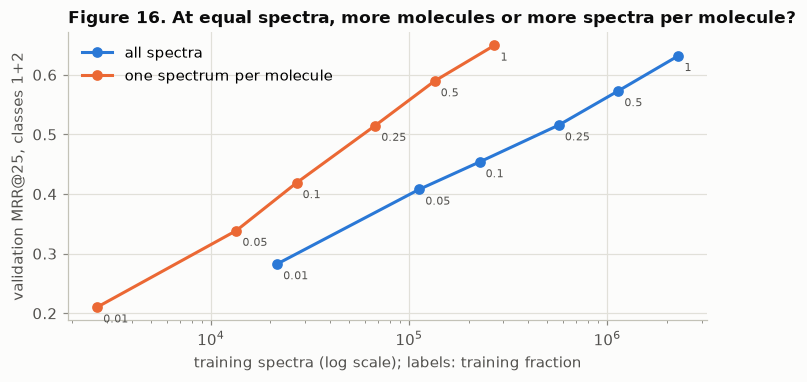

In [37]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for series, runs, colour in [("all spectra", SCALE, BLUE), ("one spectrum per molecule", SCALE_ONE, ORANGE)]:
    x = [runs[f].summary["train"]["spectra"] for f in fractions]
    y = [runs[f].mrr() for f in fractions]
    ax.plot(x, y, marker="o", color=colour, label=series)
    for f, xi, yi in zip(fractions, x, y):
        ax.annotate(f"{f:g}", (xi, yi), textcoords="offset points", xytext=(4, -10), fontsize=7, color=INK_SOFT)
ax.set_xscale("log")
ax.set_xlabel("training spectra (log scale); labels: training fraction")
ax.set_ylabel("validation MRR@25, classes 1+2")
ax.set_title("Figure 16. At equal spectra, more molecules or more spectra per molecule?")
ax.legend()
plt.show()

## 9. Model size against data volume

What network size suits how much data? Each width in the grid is trained on each subset. Parameters are counted two ways: all of them, and the ones a spectrum actually uses
(its input rows plus the dense layers), which is what sets the compute.

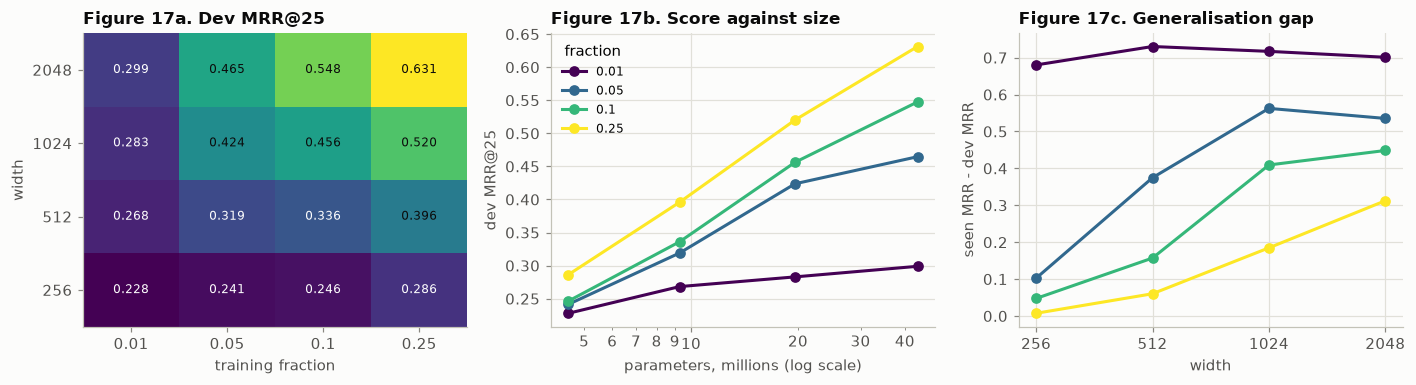

fraction,molecules,best width on dev,dev MRR,val MRR
f64,i64,i64,f64,f64
0.010,2673,2048,0.299,0.290
0.050,13470,2048,0.465,0.452
0.100,27101,2048,0.548,0.544
0.250,67620,2048,0.631,0.645


In [38]:
WIDTH_RUNS = {(w, f): run(f"width {w}, fraction {f}", replace(BASE, width=w, fraction=f))
        for w in PLAN["grid_widths"] for f in PLAN["grid_fractions"]}
grid_rows = [{"width": w, "fraction": f, "molecules": r.summary["train"]["molecules"], "params (M)": r.summary["train"]["params"] / 1e6,
              "dense params (M)": r.summary["train"]["dense_params"] / 1e6, "dev MRR": r.summary["dev"]["mrr"], "val MRR": r.mrr(),
              "seen MRR": r.summary["seen"]["mrr"], "gap (seen - dev)": r.summary["seen"]["mrr"] - r.summary["dev"]["mrr"],
              "train PFLOP": r.summary["train"]["train_flops"] / 1e15, "minutes": r.summary["train"]["seconds"] / 60}
             for (w, f), r in WIDTH_RUNS.items()]
GRID_TABLE = pl.DataFrame(grid_rows)
widths, gfractions = PLAN["grid_widths"], PLAN["grid_fractions"]
best_width = (GRID_TABLE.sort("dev MRR", descending=True).group_by("fraction", maintain_order=True).first()
              .sort("fraction").select("fraction", "molecules", pl.col("width").alias("best width on dev"), "dev MRR", "val MRR"))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
matrix = np.array([[WIDTH_RUNS[(w, f)].summary["dev"]["mrr"] for f in gfractions] for w in widths])
image = axes[0].imshow(matrix, cmap="viridis", aspect="auto", origin="lower")
axes[0].set_xticks(range(len(gfractions)), [f"{f:g}" for f in gfractions])
axes[0].set_yticks(range(len(widths)), [str(w) for w in widths])
for i in range(len(widths)):
    for j in range(len(gfractions)):
        axes[0].text(j, i, f"{matrix[i, j]:.3f}", ha="center", va="center", fontsize=8,
                     color="white" if matrix[i, j] < matrix.mean() else INK)
axes[0].set_xlabel("training fraction")
axes[0].set_ylabel("width")
axes[0].set_title("Figure 17a. Dev MRR@25")
axes[0].grid(False)
cmap = plt.get_cmap("viridis")
for j, f in enumerate(gfractions):
    sub = GRID_TABLE.filter(pl.col("fraction") == f).sort("width")
    colour = cmap(j / max(len(gfractions) - 1, 1))
    axes[1].plot(sub["params (M)"], sub["dev MRR"], marker="o", color=colour, label=f"{f:g}")
    axes[2].plot(sub["width"], sub["gap (seen - dev)"], marker="o", color=colour)
axes[1].set_xscale("log")
axes[1].xaxis.set_major_formatter(PLAIN)
axes[1].xaxis.set_minor_formatter(PLAIN)
axes[1].set_xlabel("parameters, millions (log scale)")
axes[1].set_ylabel("dev MRR@25")
axes[1].set_title("Figure 17b. Score against size")
axes[1].legend(title="fraction", fontsize=8)
axes[2].set_xscale("log", base=2)
axes[2].set_xticks(widths, [str(w) for w in widths])
axes[2].set_xlabel("width")
axes[2].set_ylabel("seen MRR - dev MRR")
axes[2].set_title("Figure 17c. Generalisation gap")
plt.tight_layout()
plt.show()
show(best_width)
if best_width.height >= 3 and best_width["best width on dev"].n_unique() > 1:
    slope = np.polyfit(np.log10(best_width["molecules"].to_numpy()), np.log2(best_width["best width on dev"].to_numpy()), 1)[0]
    print(f"best width doubles about every {10 ** (1 / slope):.1f}x more training molecules (fit over {best_width.height} subsets; "
          "widths are a coarse grid, so this is indicative only)" if slope > 0 else "best width does not grow with data in this grid")

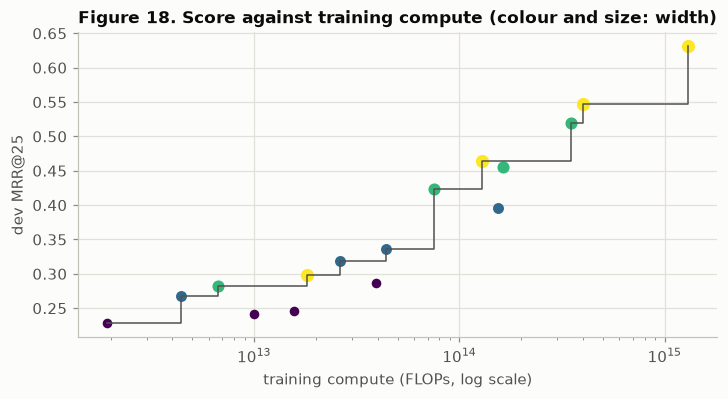

In [39]:
# Compute-optimal frontier: the best dev score reachable for a given training compute, over all runs so far.
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for r in WIDTH_RUNS.values():
    w = r.cfg.width
    ax.scatter(r.summary["train"]["train_flops"], r.summary["dev"]["mrr"], s=18 + 10 * np.log2(w / 128),
               color=plt.get_cmap("viridis")(widths.index(w) / max(len(widths) - 1, 1)))
flops = np.array([r.summary["train"]["train_flops"] for r in WIDTH_RUNS.values()])
scores = np.array([r.summary["dev"]["mrr"] for r in WIDTH_RUNS.values()])
order = np.argsort(flops)
ax.plot(flops[order], np.maximum.accumulate(scores[order]), color=INK_SOFT, linewidth=1, drawstyle="steps-post")
ax.set_xscale("log")
ax.set_xlabel("training compute (FLOPs, log scale)")
ax.set_ylabel("dev MRR@25")
ax.set_title("Figure 18. Score against training compute (colour and size: width)")
plt.show()

Two things the grid does not vary, and which bias it: dropout and learning rate are fixed at the
base values for every width. A wide network on little data might do better with more dropout, so
the best width at small fractions is a lower bound.

## 10. Compute

### 10.1 Measurements on this machine

Measured once per device and saved in `results/mlp/compute.json`, so CPU and GPU results from
different machines end up in the same figures.

In [40]:
COMPUTE_FILE = RESULTS_DIR / "compute.json"
COMPUTE = json.loads(COMPUTE_FILE.read_text()) if COMPUTE_FILE.exists() else {}


def time_steps(cfg: Config, train: SpectraSet, batch_size: int, device, steps: int = 12, warmup: int = 3) -> dict:
    # Seconds per training step: total, and the part spent building the batch on the CPU.
    rows = training_rows(train, cfg)
    model = build_model(cfg, np.full(FP_BITS, 0.02), device)
    optimisers = make_optimisers(model, cfg)
    rng = np.random.default_rng(0)
    batch_size = min(batch_size, len(rows))
    feature, total = 0.0, 0.0
    if device.type == "cuda":
        torch.cuda.reset_peak_memory_stats()
    for i in range(warmup + steps):
        batch = rng.choice(rows, size=batch_size, replace=False)
        if device.type == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        x, y = batch_tensors(train, batch, cfg, device), batch_targets(train, batch, device)
        t1 = time.perf_counter()
        loss = F.binary_cross_entropy_with_logits(model(*x), y)
        for o in optimisers:
            o.zero_grad(set_to_none=True)
        loss.backward()
        for o in optimisers:
            o.step()
        if device.type == "cuda":
            torch.cuda.synchronize()
        if i >= warmup:
            feature += t1 - t0
            total += time.perf_counter() - t0
    out = {"seconds_per_step": total / steps, "feature_seconds_per_step": feature / steps,
           "spectra_per_second": batch_size * steps / total}
    if device.type == "cuda":
        out["peak_gpu_mb"] = torch.cuda.max_memory_allocated() / 1e6
    del model, optimisers
    return out


if RETRAIN or DEVICE_NAME not in COMPUTE:
    train = training_data(BASE.fraction)
    result = {"device": DEVICE_NAME, "cpu_count": os.cpu_count()}
    started = time.perf_counter()
    result["batch_size"] = {b: time_steps(BASE, train, b, DEVICE) for b in [64, 128, 256, 512, 1024, 2048, 4096]}
    if DEVICE.type == "cuda":     # the same model on this machine's CPU, for comparison
        result["batch_size_cpu"] = {b: time_steps(BASE, train, b, torch.device("cpu"), steps=4) for b in [128, 512, 2048]}
    threads_before = torch.get_num_threads()
    counts = sorted({1, 2, 4, 8, 16, 32, threads_before} & set(range(1, (os.cpu_count() or 1) + 1)))
    result["threads"] = {}
    for n in counts:
        torch.set_num_threads(n)
        result["threads"][n] = time_steps(BASE, train, 512, torch.device("cpu"), steps=6)
    torch.set_num_threads(threads_before)
    result["input_layer"] = {f"{width} Da, {'sparse' if sparse else 'dense'}": time_steps(replace(BASE, bin_width=width, sparse_grad=sparse), train, 512, DEVICE, steps=6)
                             for width in [0.1, 0.01] for sparse in [False, True]}
    result["scoring"] = {}      # one query molecule against n real fingerprints: gather their bits, then score
    rng = np.random.default_rng(0)
    z = rng.normal(-4, 2, size=(1, FP_BITS)).astype(np.float32)
    for n_cand in [10, 100, 1_000, 10_000, 100_000]:
        mols = rng.choice(len(FP), size=min(n_cand, len(FP)), replace=False)
        t0 = time.perf_counter()
        for _ in range(3):
            owner, pos = gather_segments(FPS.ptr, mols)
            c = Candidates(mols, np.zeros(len(mols), dtype=np.int64), np.array([0, len(mols)]), np.array([-1]),
                           owner.astype(np.int32), FPS.idx[pos])
            fingerprint_scores(c, z, "tanimoto")
        result["scoring"][len(mols)] = (time.perf_counter() - t0) / 3
    result["minutes"] = (time.perf_counter() - started) / 60
    COMPUTE[DEVICE_NAME] = json.loads(json.dumps(result))      # keys become strings, as when read back
    COMPUTE_FILE.write_text(json.dumps(COMPUTE, indent=2))
print("devices measured:", list(COMPUTE))

devices measured: ['NVIDIA GeForce RTX 4080']


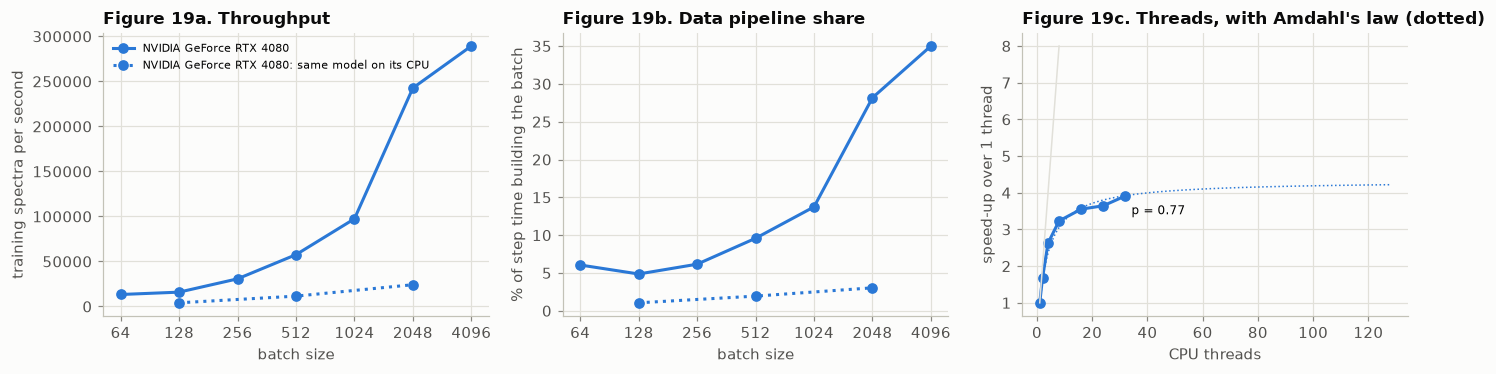

input layer,ms per step,spectra/s,GPU MB
str,f64,f64,f64
"""0.1 Da, dense""",5.277,97016.858,570.815
"""0.1 Da, sparse""",3.878,132035.330,555.163
"""0.01 Da, dense""",24.907,20556.429,3340.223
"""0.01 Da, sparse""",3.957,129384.958,2309.848


In [41]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
palette = [BLUE, ORANGE, AQUA, PURPLE]
for i, (device, result) in enumerate(COMPUTE.items()):
    series = [(device, result["batch_size"])] + ([(f"{device}: same model on its CPU", result["batch_size_cpu"])] if "batch_size_cpu" in result else [])
    for j, (label, values) in enumerate(series):
        sizes = sorted(int(b) for b in values)
        axes[0].plot(sizes, [values[str(b)]["spectra_per_second"] for b in sizes], marker="o", color=palette[i % 4],
                     linestyle="-" if j == 0 else ":", label=label)
        axes[1].plot(sizes, [values[str(b)]["feature_seconds_per_step"] / values[str(b)]["seconds_per_step"] * 100 for b in sizes],
                     marker="o", color=palette[i % 4], linestyle="-" if j == 0 else ":")
    threads = sorted(int(n) for n in result["threads"])
    t1 = result["threads"]["1"]["seconds_per_step"]
    speedup = np.array([t1 / result["threads"][str(n)]["seconds_per_step"] for n in threads])
    axes[2].plot(threads, speedup, marker="o", color=palette[i % 4], label=device)
    if len(threads) > 1:     # Amdahl's law: speedup(n) = 1 / ((1 - p) + p / n); least squares over p
        ps = np.linspace(0, 1, 1001)
        p = ps[np.argmin([((1 / ((1 - q) + q / np.array(threads)) - speedup) ** 2).sum() for q in ps])]
        result["amdahl_p"] = float(p)
        n = np.linspace(1, max(threads) * 4, 100)
        axes[2].plot(n, 1 / ((1 - p) + p / n), ":", color=palette[i % 4], linewidth=1)
        axes[2].annotate(f"p = {p:.2f}", (threads[-1], speedup[-1]), textcoords="offset points", xytext=(4, -12), fontsize=8)
axes[0].set_xscale("log", base=2)
axes[0].xaxis.set_major_formatter(PLAIN)
axes[0].set_xlabel("batch size")
axes[0].set_ylabel("training spectra per second")
axes[0].set_title("Figure 19a. Throughput")
axes[0].legend(fontsize=7)
axes[1].set_xscale("log", base=2)
axes[1].xaxis.set_major_formatter(PLAIN)
axes[1].set_xlabel("batch size")
axes[1].set_ylabel("% of step time building the batch")
axes[1].set_title("Figure 19b. Data pipeline share")
axes[2].plot([1, 8], [1, 8], color=GRID, linewidth=1)
axes[2].set_xlabel("CPU threads")
axes[2].set_ylabel("speed-up over 1 thread")
axes[2].set_title("Figure 19c. Threads, with Amdahl's law (dotted)")
plt.tight_layout()
plt.show()

here = COMPUTE[DEVICE_NAME]
show(pl.DataFrame([{"input layer": k, "ms per step": v["seconds_per_step"] * 1000, "spectra/s": v["spectra_per_second"],
                    "GPU MB": v.get("peak_gpu_mb")} for k, v in here["input_layer"].items()]))

Amdahl's law, $S(n) = 1/\big((1-p) + p/n\big)$, fits the fraction $p$ of a step that parallelises;
$1/(1-p)$ is the most any number of threads can give. The input-layer table measures what sparse
gradients save at fine bins: a dense gradient touches every row of $E$ on every step (and Adam then
updates all of them), a sparse one only the rows of the peaks in the batch.

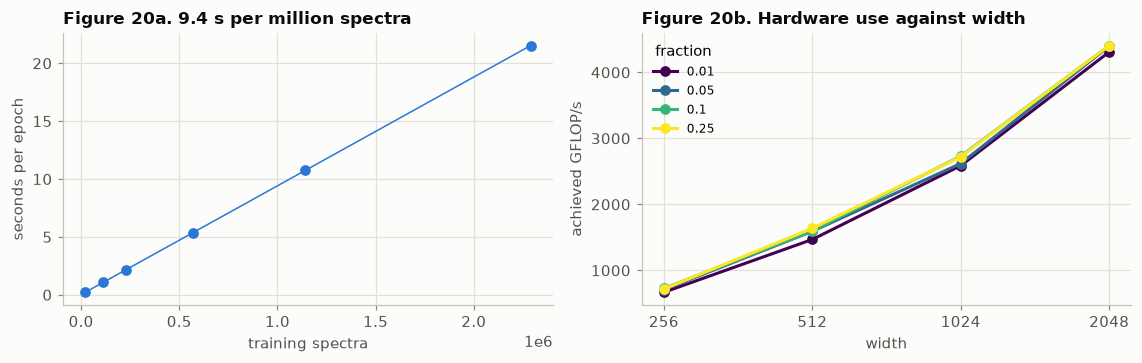

In [42]:
# Epoch time against data and against model size, from the training runs above.
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 3.4))
spectra = np.array([SCALE[f].summary["train"]["spectra"] for f in fractions])
seconds = np.array([SCALE[f].summary["train"]["seconds_per_epoch"] for f in fractions])
slope, intercept = np.polyfit(spectra, seconds, 1) if len(fractions) > 1 else (seconds[0] / spectra[0], 0.0)
left.plot(spectra, seconds, "o", color=BLUE)
left.plot(spectra, slope * spectra + intercept, color=BLUE, linewidth=1)
left.set_xlabel("training spectra")
left.set_ylabel("seconds per epoch")
left.set_title(f"Figure 20a. {slope * 1e6:.1f} s per million spectra")
for j, f in enumerate(gfractions):
    sub = sorted(((r.summary["train"]["train_flops"] / r.summary["train"]["epochs"] / r.summary["train"]["seconds_per_epoch"] / 1e9, r.cfg.width)
                  for (w, ff), r in WIDTH_RUNS.items() if ff == f), key=lambda t: t[1])
    right.plot([w for _, w in sub], [g for g, _ in sub], marker="o", label=f"{f:g}",
               color=plt.get_cmap("viridis")(j / max(len(gfractions) - 1, 1)))
right.set_xscale("log", base=2)
right.set_xticks(widths, [str(w) for w in widths])
right.set_xlabel("width")
right.set_ylabel("achieved GFLOP/s")
right.set_title("Figure 20b. Hardware use against width")
right.legend(title="fraction", fontsize=8)
plt.tight_layout()
plt.show()
SECONDS_PER_SPECTRUM_EPOCH = slope

### 10.2 What 1000 times the data would need

Each line combines a measurement from this notebook with a stated assumption. Training cost is
taken as linear in spectra (figure 20a), with as many epochs as the largest run needed.

In [43]:
def duration(seconds: float) -> str:
    for unit, size in [("days", 86400), ("h", 3600), ("min", 60)]:
        if seconds >= size:
            return f"{seconds / size:,.1f} {unit}"
    return f"{seconds:.2g} s"


def size(n_bytes: float) -> str:
    for unit, scale in [("TB", 1e12), ("GB", 1e9), ("MB", 1e6)]:
        if n_bytes >= scale:
            return f"{n_bytes / scale:,.1f} {unit}"
    return f"{n_bytes / 1e3:.1f} kB"


full = molecules.filter(~pl.col("is_dev") & (pl.col("n_train_spectra") > 0))
n_spectra_full = int(full["n_train_spectra"].sum())
largest = SCALE[fractions[-1]].summary["train"]
epochs = largest["best_epoch"] + BASE.patience
loaded = training_data(BASE.fraction)
bytes_per_spectrum = loaded.nbytes() / loaded.n
throughput = here["batch_size"]["512"]["spectra_per_second"]
step_seconds = here["batch_size"]["512"]["seconds_per_step"]
dense_bytes = base.summary["train"]["dense_params"] * 4
median_candidates = float(VAL_SIZES["n_candidates"].median())
n_measured = np.array([int(k) for k in here["scoring"]], dtype=float)
per_candidate, fixed = np.polyfit(n_measured, np.array(list(here["scoring"].values())), 1)     # time = fixed + per_candidate * n
p = here.get("amdahl_p", 0.9)
allreduce = 2 * dense_bytes / 1.25e9          # ring all-reduce moves about twice the gradient; 10 Gb/s = 1.25 GB/s
scale_rows = [
    ("training spectra", f"{n_spectra_full:,}", f"{n_spectra_full * 1000:,}", "counted"),
    ("spectra in memory as flat peak arrays", size(n_spectra_full * bytes_per_spectrum), size(n_spectra_full * bytes_per_spectrum * 1000),
     f"{bytes_per_spectrum:.0f} bytes per spectrum, measured"),
    ("one epoch on this device", duration(n_spectra_full / throughput), duration(n_spectra_full * 1000 / throughput),
     f"{throughput:,.0f} spectra/s at batch 512, measured"),
    ("whole training run on this device", duration(epochs * n_spectra_full / throughput), duration(epochs * n_spectra_full * 1000 / throughput),
     f"{epochs} epochs (largest run's best epoch + patience)"),
    ("gradient to all-reduce per step (dense layers)", size(dense_bytes), size(dense_bytes),
     "set by the model, not the data; the input layer's sparse rows can stay sharded"),
    ("all-reduce time per step over 10 Gb/s", duration(allreduce), duration(allreduce),
     f"compare {duration(step_seconds)} of compute per step here"),
    ("speed-up from 8 workers, if a step parallelises like threads", f"{1 / ((1 - p) + p / 8):.1f}x", f"{1 / ((1 - p) + p / 8):.1f}x",
     f"Amdahl's law with p = {p:.2f} (figure 19c)"),
    ("candidates per query (median)", f"{median_candidates:,.0f}", f"{median_candidates * 1000:,.0f}", "if the candidate pool grew 1000x too"),
    ("scoring time per query", duration(fixed + per_candidate * median_candidates), duration(fixed + per_candidate * median_candidates * 1000),
     f"linear fit to timings up to {int(n_measured.max()):,} candidates"),
]
show(pl.DataFrame(scale_rows, schema=["quantity", "today", "at 1000x", "basis"], orient="row"))

loaded 2,289,876 training spectra (fraction 1.0) in 2 s; 1,132 MB, 494 bytes per spectrum


quantity,today,at 1000x,basis
str,str,str,str
"""training spectra""","""2,289,876""","""2,289,876,000""","""counted"""
"""spectra in memory as flat peak arrays""","""1.1 GB""","""1.1 TB""","""494 bytes per spectrum, measured"""
"""one epoch on this device""","""40 s""","""11.1 h""","""57,526 spectra/s at batch 512, measured"""
"""whole training run on this device""","""13.9 min""","""9.7 days""","""21 epochs (largest run's best epoch + patience)"""
"""gradient to all-reduce per step (dense layers)""","""16.9 MB""","""16.9 MB""","""set by the model, not the data; the input layer's sparse row…"
"""all-reduce time per step over 10 Gb/s""","""0.027 s""","""0.027 s""","""compare 0.0089 s of compute per step here"""
"""speed-up from 8 workers, if a step parallelises like threads""","""3.1x""","""3.1x""","""Amdahl's law with p = 0.77 (figure 19c)"""
"""candidates per query (median)""","""73""","""73,000""","""if the candidate pool grew 1000x too"""
"""scoring time per query""","""-3.8e-06 s""","""0.063 s""","""linear fit to timings up to 100,000 candidates"""


What changes at 1000 times:

* **Data no longer fits in memory**, so batches stream from 01's row-group files instead of flat
  arrays; the batch builder already works on any slice of spectra, so this is a loader change.
* **Training becomes data-parallel.** Each worker takes a share of every batch; only the dense
  layers' gradient is summed across workers each step. Its size depends on the width, not the data,
  so communication per step stays constant while compute per worker shrinks: the step time and the
  all-reduce time above say how many workers pay off.
* **The input layer is the one piece that grows with resolution** (15,026 rows at 0.1 Da, 150,251 at
  0.01 Da), and its gradient is sparse, so it can be sharded across workers rather than copied.
* **Candidate scoring is embarrassingly parallel**: shard the fingerprint table by mass, send each
  query only to the shards its window touches (map), merge the top 25 (reduce).

## 11. Robustness

In [44]:
seed_rows = [{"seed": s, "dev MRR": r.summary["dev"]["mrr"], "val MRR, classes 1+2": r.mrr(), "class 1": r.mrr("class 1"),
              "class 2": r.mrr("class 2"), "natural products": r.mrr("natural products")} for s, r in SEED_RUNS.items()]
show(pl.DataFrame(seed_rows))
ci = base.summary["val"]["classes 1+2"]
print(f"bootstrap 95% interval of the base run (molecules resampled): {ci['mrr_low']:.3f} to {ci['mrr_high']:.3f}; "
      f"seed standard deviation: {seed_spread:.3f}")

seed,dev MRR,"val MRR, classes 1+2",class 1,class 2,natural products
i64,f64,f64,f64,f64,f64
0,0.424,0.408,0.411,0.404,0.382
1,0.422,0.411,0.418,0.403,0.396
2,0.436,0.418,0.417,0.419,0.352


bootstrap 95% interval of the base run (molecules resampled): 0.391 to 0.426; seed standard deviation: 0.005


The seed spread and the bootstrap interval measure different noise: the first the training run,
the second which molecules happen to be in the validation set. Section 7 uses paired differences,
which cancel the second, and compares them with the first.

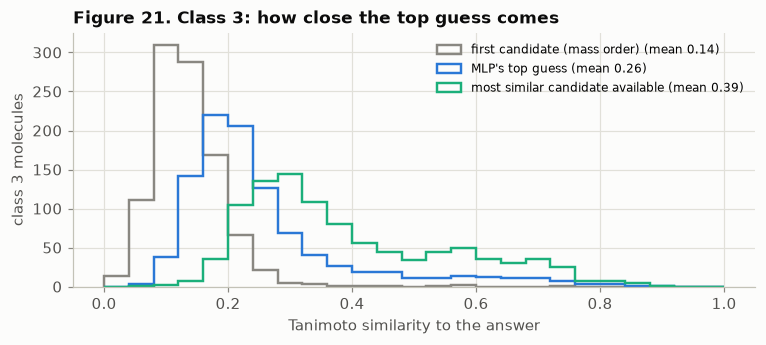

In [45]:
# Class 3: no correct answer is a candidate. Is the top guess at least a close relative?
c3 = base.val.filter(pl.col("sim_class") == 3).select("inchikey14", "top1_tanimoto")
c = candidates(VAL, fps=FPS)
similarity = oracle_score(VAL, FPS)(c)              # every candidate's Tanimoto similarity to the answer
n_cand = np.diff(c.start)
nonempty = np.flatnonzero(n_cand > 0)
most_similar = np.full(VAL.n, np.nan)
most_similar[nonempty] = np.maximum.reduceat(similarity, c.start[nonempty])
best_available = most_similar[(VAL.table["sim_class"] == 3).fill_null(False).to_numpy()]
fig, ax = plt.subplots(figsize=(8, 3))
edges = np.linspace(0, 1, 26)
for values, colour, label in [(BASELINES["random order"].filter(pl.col("sim_class") == 3)["top1_tanimoto"].drop_nulls().drop_nans(), GREY, "first candidate (mass order)"),
                              (c3["top1_tanimoto"].drop_nulls().drop_nans(), BLUE, "MLP's top guess"),
                              (pl.Series(best_available, dtype=pl.Float64).drop_nans(), AQUA, "most similar candidate available")]:
    if len(values):
        ax.hist(values.to_numpy(), bins=edges, histtype="step", linewidth=1.6, color=colour, label=f"{label} (mean {values.mean():.2f})")
ax.set_xlabel("Tanimoto similarity to the answer")
ax.set_ylabel("class 3 molecules")
ax.set_title("Figure 21. Class 3: how close the top guess comes")
ax.legend(fontsize=8)
plt.show()

## 12. Final model and the results files for 05

The final model takes, for each choice in section 7, the option with the best **dev** score, and
the best width on dev at the largest grid subset, then trains on the largest subset. Combining
separately chosen options assumes they do not interact; that is not tested here.

In [46]:
def best_on_dev(field: str, options: dict[str, Run]):
    # options: label -> run; returns the field value of the run with the best dev MRR.
    label = max(options, key=lambda k: options[k].summary["dev"]["mrr"])
    return getattr(options[label].cfg, field), label


choices = {}
for field, labels in {"loss": ["weighted BCE", "focal loss", "soft Tanimoto loss", "BCE + 0.1 Tanimoto"],
                      "intensity": ["raw intensity", "log intensity", "peak presence only"],
                      "neutral_losses": ["+ neutral losses"], "metadata": ["no metadata"],
                      "dropout": ["no dropout", "dropout 0.5"],
                      "depth": ["depth 2 (one hidden block)", "depth 5 (four hidden blocks)"]}.items():
    value, label = best_on_dev(field, {"base": base, **{l: ABLATION_RUNS[l] for l in labels}})
    choices[field] = value
width_rows = GRID_TABLE.filter(pl.col("fraction") == max(gfractions)).sort("dev MRR", descending=True)
choices["width"] = int(width_rows["width"][0])
FINAL = replace(BASE, fraction=FINAL_FRACTION, **choices)
print("final settings:", {k: v for k, v in asdict(FINAL).items() if v != getattr(BASE, k)})
print(f"scoring: {BEST_SCORING['scoring']}, aggregate: {BEST_SCORING['aggregate']} (best on dev, section 7.2)")
final = run("final", FINAL, keep_model=True)

final settings: {'fraction': 1.0, 'intensity': 'log', 'width': 2048, 'depth': 5, 'loss': 'wbce'}
scoring: tanimoto, aggregate: mean_prob (best on dev, section 7.2)


C:\Users\892hf\AppData\Local\Temp\ipykernel_25124\1991882297.py:31: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(weights, map_location=DEVI

In [47]:
TEST = query_set("test", heldout.filter(pl.col("split") == "test").select(SPECTRUM_COLUMNS))
CANDIDATE_NAMES = molecules.select(pl.col("mol").cast(pl.Int64).alias("candidate_mol"), pl.col("inchikey14").alias("candidate_inchikey14"),
                                   pl.col("smiles").alias("candidate_smiles"))
final_dir = RESULTS_DIR / "final"
final_dir.mkdir(parents=True, exist_ok=True)
for qs in (VAL, TEST):
    logits = predict(final.model, qs.spectra, FINAL)
    per_molecule, tops = rank_queries(qs, model_score(qs, logits, BEST_SCORING["scoring"], BEST_SCORING["aggregate"]), keep_top=TOP_K)
    ranked = (tops.join(qs.table.select(pl.col("mol").cast(pl.Int64), "inchikey14", "sim_class", "pool"), on="mol")
              .join(CANDIDATE_NAMES, on="candidate_mol")
              .select("inchikey14", "sim_class", "pool", "rank", "candidate_inchikey14", "candidate_smiles", "score")
              .sort("inchikey14", "rank"))
    ranked.write_parquet(final_dir / f"{qs.name}_top{TOP_K}.parquet")
    if qs.name == "val":
        FINAL_VAL = summarise(per_molecule)
summary = {"model": "fingerprint MLP", "config": asdict(FINAL), "scoring": BEST_SCORING["scoring"], "aggregate": BEST_SCORING["aggregate"],
           "val": FINAL_VAL, "train": final.summary["train"], "files": [f"val_top{TOP_K}.parquet", f"test_top{TOP_K}.parquet"],
           "note": "test rankings are written here and scored only in 05"}
(final_dir / "summary.json").write_text(json.dumps(summary, indent=2))
show(summary_table({"final MLP": FINAL_VAL, "base MLP": base.summary["val"], "nearest mass": RESULTS["nearest mass"],
                    "oracle fingerprint": RESULTS["oracle fingerprint (ceiling)"]}))
print("written:", *sorted(p.name for p in final_dir.iterdir()))

method,group,molecules,MRR@25,95% CI,hit@1,hit@5,hit@25
str,str,i64,f64,str,f64,f64,f64
"""final MLP""","""class 1""",1038,0.835,"""0.817 to 0.853""",0.750,0.937,0.990
"""final MLP""","""class 2""",961,0.747,"""0.727 to 0.769""",0.627,0.894,0.970
"""final MLP""","""natural products""",126,0.751,"""0.689 to 0.812""",0.643,0.849,0.984
"""final MLP""","""classes 1+2""",1999,0.793,"""0.778 to 0.807""",0.691,0.916,0.980
"""base MLP""","""class 1""",1038,0.411,"""0.387 to 0.436""",0.280,0.566,0.836
"""base MLP""","""class 2""",961,0.404,"""0.378 to 0.430""",0.284,0.536,0.806
"""base MLP""","""natural products""",126,0.382,"""0.320 to 0.445""",0.226,0.556,0.873
"""base MLP""","""classes 1+2""",1999,0.408,"""0.391 to 0.426""",0.282,0.552,0.822
"""nearest mass""","""class 1""",1038,0.175,"""0.162 to 0.189""",0.076,0.274,0.626


written: summary.json test_top25.parquet val_top25.parquet


## 13. The group's shared splits

The CNN, DreaMS and MS2DeepScore strands train on Michael's shared splits
(`MichaelM/Small_data_split.ipynb`). `stage_1_5pct` takes 5% of the spectra in every part file and
splits them 80/20 **by spectrum** (seed 42); `stage_2_9pct` adds as many training spectra again
and keeps the same validation spectra. The other strands score only the validation spectra whose
molecule is in training (44% at 5%, 63% at 9%), as classification over the training molecules.
To compare like with like, the MLP is trained here on the same spectra and scored on the same
validation spectra with the same metrics. The split in use is set by `GROUP_SPLIT_DIR` and printed
below. Differences from sections 6 to 12:

* Each validation spectrum is scored on its own, as the classifiers do; spectra are not pooled per molecule.
* Candidates are the training split's molecules: the classifiers' label set. Scored over all of them
  (the classifiers' setting), and over those within ±10 ppm of the spectrum's neutral mass (this
  notebook's setting; the same filter could be applied to a classifier's outputs).
* The settings are the final ones (section 12), with the width that was best on dev (section 9) at
  the training fraction nearest this split's share of the training spectra.
  Early stopping still uses dev, so the few training spectra of dev molecules are left out.
* The scoring rule (section 7.2) is picked again on dev, once per candidate setting: a rule chosen
  inside a mass window need not suit candidates of every size.

The split is by spectrum, so most known-molecule validation spectra have a sibling (same molecule,
another energy, adduct or instrument) in training. These scores measure recognition of seen
molecules and are not comparable with sections 6 to 12, which score unseen molecules. The other
validation spectra belong to molecules outside the training split. A classifier cannot name
them; the MLP can rank them if their structures are candidates, so they are scored with the
validation molecules added to the candidates.

In [48]:
def find_group_split() -> Path | None:
    options = [os.environ.get("GROUP_SPLIT_DIR"), REPO / "model_datasets" / "stage_1_5pct",
               DERIVED_DIR / "stage_1_5pct", REPO / "stage_1_5pct"]
    return next((Path(p) for p in options if p and (Path(p) / "train.parquet").exists()), None)


GROUP_DIR = find_group_split()
if GROUP_DIR is None:
    print("stage_1_5pct not found, so section 13 is skipped. Set GROUP_SPLIT_DIR to Michael's folder to run it.")
else:
    def group_frame(name: str) -> pl.DataFrame:
        frame = (pl.read_parquet(GROUP_DIR / f"{name}.parquet", columns=SPECTRUM_COLUMNS)
                 .filter(pl.col("mzs").list.len() > 0)
                 .join(molecules.select("inchikey14", "mol", "is_dev"), on="inchikey14", how="left")
                 .with_columns(pl.lit(0.0).alias("train_subset_rank")))
        missing = frame["mol"].null_count()
        assert missing == 0, f"{missing} {name} spectra have no molecule in 01's molecules.parquet: is the split from the same 01 run?"
        return frame

    g_train, g_val = group_frame("train"), group_frame("validation")
    train_keys = g_train.select("inchikey14").unique().with_columns(pl.lit(True).alias("known"))
    g_val = g_val.join(train_keys, on="inchikey14", how="left").with_columns(pl.col("known").fill_null(False))
    G_KNOWN = g_val["known"].to_numpy()
    CLASS_MOLS = np.unique(g_train["mol"].to_numpy()).astype(np.int64)                 # the classifiers' label set
    OPEN_MOLS = np.unique(np.concatenate([CLASS_MOLS, g_val["mol"].to_numpy()])).astype(np.int64)
    G_MASS = neutral_masses(g_val["precursor_mz"].to_numpy(), g_val["adduct"].to_list())
    GROUP_TRAIN = load_spectra(g_train.filter(~pl.col("is_dev")))
    GROUP_VAL = load_spectra(g_val)
    print(f"split folder: {GROUP_DIR}")
    print(f"training: {g_train.height:,} spectra of {len(CLASS_MOLS):,} molecules; the MLP leaves out "
          f"{g_train.height - GROUP_TRAIN.n:,} spectra of {g_train.filter(pl.col('is_dev'))['mol'].n_unique():,} dev molecules")
    print(f"validation: {g_val.height:,} spectra; {G_KNOWN.sum():,} ({G_KNOWN.mean():.1%}) of molecules in training "
          f"({g_val.filter(pl.col('known'))['mol'].n_unique():,} molecules), {(~G_KNOWN).sum():,} of molecules outside it "
          f"({g_val.filter(~pl.col('known'))['mol'].n_unique():,} molecules)")

split folder: D:\Data Science Toolbox\Group Sprints\Sprint 2\gpu_run_package\DreaMS_project\model_datasets\stage_2_9pct
training: 179,108 spectra of 107,862 molecules; the MLP leaves out 498 spectra of 378 dev molecules
validation: 22,963 spectra; 13,550 (59.0%) of molecules in training (10,980 molecules), 9,413 of molecules outside it (9,081 molecules)


### 13.1 Scoring every spectrum against tens of thousands of candidates

Sections 3 to 12 score a few hundred candidates per molecule from their set bits. Here every
spectrum meets up to every training molecule, so scores are one dense matrix product per batch of
spectra on the GPU. Each distinct fingerprint is scored once and copied to the molecules that share
it, so identical fingerprints tie exactly and the tie rule of section 3.4 holds. Balanced accuracy
is the mean over validation molecules of their top-1 rate; macro F1 needs one hard guess per
spectrum, so ties are broken by a fixed random order of the candidates.

So that the run can be plotted like the other strands' training curves, after every epoch the
loss and top-1 are also recorded on the known-molecule validation spectra and on a fixed sample
of 10,000 training spectra (`history.csv`). This only evaluates the network; training and early
stopping (on dev) are unchanged.

In [49]:
def rank_spectra(logits: np.ndarray, truth_mol: np.ndarray, mass: np.ndarray, cand: np.ndarray,
                 ppm: float | None, scoring: str, chunk: int = 512, seed: int = 0) -> pl.DataFrame:
    # One query per spectrum. cand: sorted candidate molecules; ppm None = every candidate, else the mass window.
    uniq, inverse = np.unique(FP[cand], axis=0, return_inverse=True)
    F = torch.from_numpy(np.unpackbits(uniq, axis=1).astype(np.float32)).to(DEVICE)
    n_set, inv = F.sum(1), torch.from_numpy(inverse.reshape(-1)).to(DEVICE)
    by_mass = np.argsort(MONO_MASS[cand], kind="stable")                # NaN masses sort last and fall in no window
    mass_pos = torch.from_numpy(np.argsort(by_mass)).to(DEVICE)        # each candidate's place in mass order
    sorted_mass = MONO_MASS[cand][by_mass]
    lo = np.searchsorted(sorted_mass, mass * (1 - (ppm or 0) * 1e-6), "left")
    hi = np.searchsorted(sorted_mass, mass * (1 + (ppm or 0) * 1e-6), "right")
    lo, hi = np.where(np.isnan(mass), 0, lo), np.where(np.isnan(mass), 0, hi)     # no mass, no window
    at = np.searchsorted(cand, truth_mol)
    truth = np.where((at < len(cand)) & (cand[np.minimum(at, len(cand) - 1)] == truth_mol), at, -1)
    perm = torch.from_numpy(np.random.default_rng(seed).permutation(len(cand))).to(DEVICE)
    n = len(truth_mol)
    g, t, n_cand, has, guess = (np.zeros(n, np.int64), np.zeros(n, np.int64), np.zeros(n, np.int64),
                                np.zeros(n, bool), np.full(n, -1, np.int64))
    guess_score = np.full(n, np.nan)
    for start in range(0, n, chunk):
        rows = slice(start, min(start + chunk, n))
        z = torch.from_numpy(logits[rows]).to(DEVICE)
        p = torch.sigmoid(z)
        if scoring == "loglik":
            s = z @ F.T
        else:
            inter = p @ F.T
            s = (inter / (p.sum(1, keepdim=True) + n_set - inter).clamp_min(1e-9) if scoring == "tanimoto"
                 else inter / (p.norm(dim=1, keepdim=True) * n_set.sqrt() + 1e-9))
        s = s[:, inv]
        if ppm is not None:
            inside = ((mass_pos[None, :] >= torch.from_numpy(lo[rows]).to(DEVICE)[:, None])
                      & (mass_pos[None, :] < torch.from_numpy(hi[rows]).to(DEVICE)[:, None]))
            s = s.masked_fill(~inside, -torch.inf)
            n_cand[rows] = inside.sum(1).cpu().numpy()
        else:
            n_cand[rows] = len(cand)
        tr = torch.from_numpy(truth[rows]).to(DEVICE)
        answer = s.gather(1, tr.clamp_min(0)[:, None])
        ok = (tr >= 0) & torch.isfinite(answer[:, 0])
        g[rows] = (s > answer).sum(1).cpu().numpy()
        t[rows] = ((s == answer).sum(1) - 1).cpu().numpy()
        has[rows] = ok.cpu().numpy()
        best = perm[s[:, perm].argmax(1)].cpu().numpy()
        guess[rows] = np.where(n_cand[rows] > 0, cand[best], -1)
        guess_score[rows] = np.where(n_cand[rows] > 0, s.max(1).values.cpu().numpy(), np.nan)
    g, t = np.where(has, g, 0), np.where(has, t, 0)
    last, first = np.minimum(g + t + 1, TOP_K), np.minimum(g + 1, TOP_K + 1)
    rr = np.where(has & (g + 1 <= TOP_K), (HARMONIC[last] - HARMONIC[first - 1]) / (t + 1), 0.0)
    hits = {f"hit{k}": np.where(has, np.clip(np.minimum(g + t + 1, k) - g, 0, None) / (t + 1), 0.0) for k in (1, 5, 25)}
    return pl.DataFrame({"mol": truth_mol, "n_candidates": n_cand, "truth_in_set": has, "above": g, "tied": t,
                         "rr": rr, **hits, "guess_mol": guess, "guess_score": guess_score})


def group_metrics(res: pl.DataFrame) -> dict:
    true, guess = res["mol"].to_numpy(), res["guess_mol"].to_numpy()
    classes, idx = np.unique(true, return_inverse=True)
    true_count = np.bincount(idx, minlength=len(classes))
    tp = np.bincount(idx[guess == true], minlength=len(classes))
    at = np.minimum(np.searchsorted(classes, guess), len(classes) - 1)
    named = classes[at] == guess                      # guesses of a molecule that is in this validation set
    guessed = np.bincount(at[named], minlength=len(classes))
    per_molecule = res.group_by("mol").agg(pl.col("hit1").mean())["hit1"]
    return {"spectra": res.height, "molecules": len(classes), "top-1": float(res["hit1"].mean()),
            "top-5": float(res["hit5"].mean()), "MRR@25": float(res["rr"].mean()), "hit@25": float(res["hit25"].mean()),
            "balanced accuracy": float(per_molecule.mean()), "macro F1": float(np.mean(2 * tp / (true_count + guessed))),
            "answer among candidates": float(res["truth_in_set"].mean()),
            "median candidates": float(np.median(res["n_candidates"].to_numpy()))}

def group_top1(logits: np.ndarray, truth_at: np.ndarray, F: torch.Tensor, n_set: torch.Tensor, inv: torch.Tensor,
               lo: np.ndarray, hi: np.ndarray, mass_pos: torch.Tensor, chunk: int = 512) -> dict:
    # rank_spectra's top-1 (ties shared) for each scoring rule, over every candidate and inside the mass window.
    totals = {}
    for start in range(0, len(logits), chunk):
        rows = slice(start, min(start + chunk, len(logits)))
        z = torch.from_numpy(logits[rows]).to(DEVICE)
        p = torch.sigmoid(z)
        inter = p @ F.T
        tr = torch.from_numpy(truth_at[rows]).to(DEVICE)[:, None]
        inside = ((mass_pos[None, :] >= torch.from_numpy(lo[rows]).to(DEVICE)[:, None])
                  & (mass_pos[None, :] < torch.from_numpy(hi[rows]).to(DEVICE)[:, None]))
        for scoring in ("tanimoto", "cosine", "loglik"):
            if scoring == "loglik":
                s = z @ F.T
            elif scoring == "tanimoto":
                s = inter / (p.sum(1, keepdim=True) + n_set - inter).clamp_min(1e-9)
            else:
                s = inter / (p.norm(dim=1, keepdim=True) * n_set.sqrt() + 1e-9)
            s = s[:, inv]
            for window, sw in (("all", s), ("window", s.masked_fill(~inside, -torch.inf))):
                answer = sw.gather(1, tr)
                above, tied = (sw > answer).sum(1), (sw == answer).sum(1) - 1
                hit = torch.where(torch.isfinite(answer[:, 0]) & (above == 0), 1.0 / (tied + 1).float(),
                                  torch.zeros_like(answer[:, 0]))
                key = f"top1_{window}_{scoring}"
                totals[key] = totals.get(key, 0.0) + float(hit.sum())
    return {k: v / len(logits) for k, v in totals.items()}


def make_group_curves(sample_size: int = 10_000):
    # Called by fit() after every epoch: loss (BCE over the fingerprint bits) and top-1 among the training
    # molecules, on the known-molecule validation spectra and on a fixed sample of training spectra, in eval mode.
    uniq, inverse = np.unique(FP[CLASS_MOLS], axis=0, return_inverse=True)
    F = torch.from_numpy(np.unpackbits(uniq, axis=1).astype(np.float32)).to(DEVICE)
    n_set, inv = F.sum(1), torch.from_numpy(inverse.reshape(-1)).to(DEVICE)
    by_mass = np.argsort(MONO_MASS[CLASS_MOLS], kind="stable")
    mass_pos = torch.from_numpy(np.argsort(by_mass)).to(DEVICE)
    sorted_mass = MONO_MASS[CLASS_MOLS][by_mass]
    frame = g_train.filter(~pl.col("is_dev"))
    sample = frame.sample(n=min(sample_size, frame.height), seed=0)
    sample_ss = load_spectra(sample)
    known = np.flatnonzero(G_KNOWN)
    prepared = []
    for label, ss, sel, mass in [("validation", GROUP_VAL, known, G_MASS[known]),
                                 ("train_sample", sample_ss, np.arange(sample_ss.n),
                                  neutral_masses(sample["precursor_mz"].to_numpy(), sample["adduct"].to_list()))]:
        mols = ss.mol[sel].astype(np.int64)
        truth_at = np.searchsorted(CLASS_MOLS, mols)
        assert (CLASS_MOLS[np.minimum(truth_at, len(CLASS_MOLS) - 1)] == mols).all()
        lo = np.searchsorted(sorted_mass, mass * (1 - PPM_WINDOW * 1e-6), "left")
        hi = np.searchsorted(sorted_mass, mass * (1 + PPM_WINDOW * 1e-6), "right")
        lo, hi = np.where(np.isnan(mass), 0, lo), np.where(np.isnan(mass), 0, hi)
        prepared.append((label, ss, sel, truth_at, lo, hi, np.unpackbits(FP[mols], axis=1).astype(np.float32)))

    def hook(model, cfg) -> dict:
        row = {}
        for label, ss, sel, truth_at, lo, hi, y in prepared:
            logits = predict(model, ss, cfg)[sel]
            row[f"{label}_bce"] = float((np.maximum(logits, 0) - logits * y + np.log1p(np.exp(-np.abs(logits)))).mean())
            row.update({f"{label}_{k}": v for k, v in group_top1(logits, truth_at, F, n_set, inv, lo, hi, mass_pos).items()})
        return row
    return hook

In [50]:
if GROUP_DIR is not None:
    # Final settings (section 12), with the width best on dev (section 9) at the grid fraction nearest
    # this split's share of all training spectra (4% for stage_1_5pct, 8% for stage_2_9pct).
    G_SHARE = g_train.height / int(molecules["n_train_spectra"].sum())
    G_FRACTION = min(gfractions, key=lambda f: abs(f - G_SHARE))
    G_WIDTH = int(GRID_TABLE.filter(pl.col("fraction") == G_FRACTION).sort("dev MRR", descending=True)["width"][0])
    GROUP_CFG = replace(FINAL, fraction=BASE.fraction, width=G_WIDTH)
    G_SETTINGS = [  # name, which validation spectra, candidates, window
        ("known molecules, all training molecules", G_KNOWN, CLASS_MOLS, None),
        (f"known molecules, training molecules within ±{PPM_WINDOW:g} ppm", G_KNOWN, CLASS_MOLS, PPM_WINDOW),
        ("unseen molecules, training + validation molecules", ~G_KNOWN, OPEN_MOLS, None),
        (f"unseen molecules, training + validation molecules within ±{PPM_WINDOW:g} ppm", ~G_KNOWN, OPEN_MOLS, PPM_WINDOW)]
    G_RESULTS = RESULTS_DIR / ("group_5pct" if GROUP_DIR.name == "stage_1_5pct" else f"group_{GROUP_DIR.name}")
    SCORINGS = ["tanimoto", "cosine", "loglik"]
    g_key = hashlib.sha1(json.dumps({"config": asdict(GROUP_CFG), "scorings": SCORINGS, "dev": DEV_SALT, "version": 2,
                                     "train": [GROUP_TRAIN.n, int(GROUP_TRAIN.row_id.sum())],
                                     "val": [GROUP_VAL.n, int(GROUP_VAL.row_id.sum())]}, sort_keys=True).encode()).hexdigest()[:10]
    saved = G_RESULTS / "summary.json"
    if not RETRAIN and saved.exists() and json.loads(saved.read_text()).get("key") == g_key:
        G_SUMMARY = json.loads(saved.read_text())
        G_PER_SPECTRUM = pl.read_parquet(G_RESULTS / "val_spectra.parquet")
        G_HISTORY = pl.read_csv(G_RESULTS / "history.csv")
        G_SCORING = G_SUMMARY["scoring"]
        print("loaded the saved group-split run", g_key)
    else:
        print("training on the group split:", {k: v for k, v in asdict(GROUP_CFG).items() if v != getattr(BASE, k)} or "base settings")
        EPOCH_HOOK = make_group_curves()      # training and validation curves, as the other strands plot them
        try:
            g_model, G_HISTORY, g_stats = fit(GROUP_CFG, GROUP_TRAIN)
        finally:
            EPOCH_HOOK = None
            gc.collect()
            if DEVICE.type == "cuda":
                torch.cuda.empty_cache()
        # The scoring rule for each candidate setting, picked on dev spectra (one query per spectrum), never on validation.
        dev_logits = predict(g_model, DEV.spectra, GROUP_CFG)
        dev_mol = DEV.spectra.mol.astype(np.int64)
        dev_mass = np.repeat(DEV.table["mass"].to_numpy(), np.diff(DEV.offsets))
        dev_cand = np.union1d(CLASS_MOLS, dev_mol)
        dev_rows, G_SCORING = [], {}
        for window_name, ppm in [("all", None), ("window", PPM_WINDOW)]:
            for scoring in SCORINGS:
                mrr = float(rank_spectra(dev_logits, dev_mol, dev_mass, dev_cand, ppm, scoring)["rr"].mean())
                dev_rows.append({"candidates": window_name, "scoring": scoring, "dev MRR@25": mrr})
            G_SCORING[window_name] = max((r for r in dev_rows if r["candidates"] == window_name), key=lambda r: r["dev MRR@25"])["scoring"]
        g_logits = predict(g_model, GROUP_VAL, GROUP_CFG)
        oracle_logits = np.where(np.unpackbits(FP[GROUP_VAL.mol], axis=1).astype(bool), 20.0, -20.0).astype(np.float32)
        frames, rows = [], []
        key_of = np.full(int(molecules["mol"].max()) + 1, "", dtype=object)
        key_of[molecules["mol"].to_numpy()] = molecules["inchikey14"].to_numpy()
        for name, mask, cand, ppm in G_SETTINGS:
            sel = np.flatnonzero(mask)
            if not len(sel):
                continue
            scoring = G_SCORING["all" if ppm is None else "window"]
            res = rank_spectra(g_logits[sel], GROUP_VAL.mol[sel].astype(np.int64), G_MASS[sel], cand, ppm, scoring)
            ceiling = rank_spectra(oracle_logits[sel], GROUP_VAL.mol[sel].astype(np.int64), G_MASS[sel], cand, ppm, scoring)
            rows.append({"setting": name, "scoring": scoring, **group_metrics(res), "ceiling top-1": float(ceiling["hit1"].mean())})
            guess = res["guess_mol"].to_numpy()
            frames.append(res.with_columns(pl.lit(name).alias("setting"), pl.Series("row_id", GROUP_VAL.row_id[sel]),
                                           pl.Series("inchikey14", key_of[res["mol"].to_numpy()].astype(str)),
                                           pl.Series("guess_inchikey14", np.where(guess >= 0, key_of[np.maximum(guess, 0)], "").astype(str))))
        G_PER_SPECTRUM = pl.concat(frames)
        G_SUMMARY = {"key": g_key, "split": str(GROUP_DIR.name), "config": asdict(GROUP_CFG), "scoring": G_SCORING,
                     "train": g_stats, "dev_scoring": dev_rows, "settings": rows, "device": DEVICE_NAME, "torch": torch.__version__,
                     "created_utc": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime())}
        G_RESULTS.mkdir(parents=True, exist_ok=True)
        G_PER_SPECTRUM.write_parquet(G_RESULTS / "val_spectra.parquet")
        G_HISTORY.write_csv(G_RESULTS / "history.csv")
        saved.write_text(json.dumps(G_SUMMARY, indent=2))
        torch.save(g_model.state_dict(), CACHE_DIR / "models" / f"{G_RESULTS.name}_{g_key}.pt")
        del g_model
        gc.collect()
    t = G_SUMMARY["train"]
    print(f"{t['spectra']:,} spectra, {t['epochs']} epochs (kept {t['best_epoch']}), {t['seconds'] / 60:.1f} min on {G_SUMMARY['device']}; "
          f"width {GROUP_CFG.width} (best on dev at fraction {G_FRACTION:g}; this split is {G_SHARE:.1%} of the training spectra)")
    print("scoring rule on dev spectra, per candidate setting:")
    show(pl.DataFrame(G_SUMMARY["dev_scoring"]).pivot(on="candidates", index="scoring", values="dev MRR@25"))
    G_TABLE = pl.DataFrame(G_SUMMARY["settings"])
    show(G_TABLE.select("setting", "scoring", "spectra", "molecules", "top-1", "top-5", "MRR@25", "balanced accuracy", "macro F1",
                        "answer among candidates", "median candidates", "ceiling top-1"))

training on the group split: {'intensity': 'log', 'width': 2048, 'depth': 5, 'loss': 'wbce'}


178,610 spectra, 24 epochs (kept 23), 1.6 min on NVIDIA GeForce RTX 4080; width 2048 (best on dev at fraction 0.1; this split is 7.8% of the training spectra)
scoring rule on dev spectra, per candidate setting:


scoring,all,window
str,f64,f64
"""tanimoto""",0.076,0.649
"""cosine""",0.078,0.656
"""loglik""",0.051,0.622


setting,scoring,spectra,molecules,top-1,top-5,MRR@25,balanced accuracy,macro F1,answer among candidates,median candidates,ceiling top-1
str,str,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""known molecules, all training molecules""","""cosine""",13550,10980,0.305,0.425,0.360,0.268,0.258,1.000,107862.000,0.973
"""known molecules, training molecules within ±10 ppm""","""cosine""",13550,10980,0.623,0.811,0.707,0.617,0.614,0.943,14.000,0.938
"""unseen molecules, training + validation molecules""","""cosine""",9413,9081,0.022,0.092,0.057,0.022,0.021,1.000,116943.000,0.980
"""unseen molecules, training + validation molecules within ±10…","""cosine""",9413,9081,0.443,0.718,0.568,0.445,0.441,0.992,28.000,0.989


*Ceiling top-1*: the score if the network predicted every fingerprint exactly. Below 1 only where
other candidates share the answer's fingerprint.

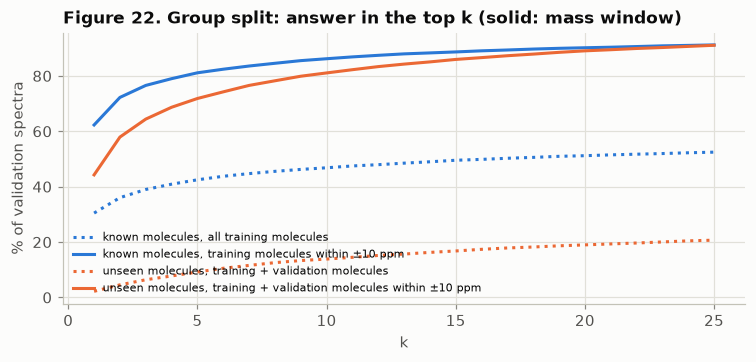

In [51]:
if GROUP_DIR is not None:
    ks = np.arange(1, TOP_K + 1)
    fig, ax = plt.subplots(figsize=(8, 3.2))
    for (name, *_), colour in zip(G_SETTINGS, [BLUE, BLUE, ORANGE, ORANGE]):
        res = G_PER_SPECTRUM.filter(pl.col("setting") == name)
        if not res.height:
            continue
        g, t, has = res["above"].to_numpy(), res["tied"].to_numpy(), res["truth_in_set"].to_numpy()
        curve = [np.where(has, np.clip(np.minimum(g + t + 1, k) - g, 0, None) / (t + 1), 0).mean() * 100 for k in ks]
        ax.plot(ks, curve, "-" if "ppm" in name else ":", color=colour, label=name)
    ax.set_xlabel("k")
    ax.set_ylabel("% of validation spectra")
    ax.set_title("Figure 22. Group split: answer in the top k (solid: mass window)")
    ax.legend(fontsize=7)
    plt.show()

### 13.2 Against the other strands

The CNN and frozen DreaMS numbers are read from their output files for the same split if they are
in the repo (`cnn_5pct_metrics.csv` or `cnn_9pct_metrics.csv`, last epoch;
`frozen_dreams_5pct/metrics.json` or `frozen_dreams_9pct/metrics.json`). All rows score the same
known-molecule validation spectra.

In [52]:
def first_match(name: str) -> Path | None:
    found = [p for depth in ["", "*/", "*/*/", "*/*/*/"] for p in REPO.glob(depth + name)
             if not p.is_relative_to(DERIVED_DIR)]
    return sorted(found)[0] if found else None


if GROUP_DIR is not None:
    mlp_rows = {row["setting"]: row for row in G_SUMMARY["settings"]}
    rows = []
    for label, name in [("fingerprint MLP", G_SETTINGS[0][0]), (f"fingerprint MLP, ±{PPM_WINDOW:g} ppm candidates", G_SETTINGS[1][0])]:
        if name in mlp_rows:
            r = mlp_rows[name]
            rows.append({"model": label, "spectra": r["spectra"], "top-1": r["top-1"], "top-5": r["top-5"],
                         "balanced accuracy": r["balanced accuracy"], "macro F1": r["macro F1"], "source": "this notebook"})
    G_TAG = GROUP_DIR.name.split("_")[-1]       # "5pct" or "9pct": which run of the other strands to read
    cnn = first_match(f"cnn_{G_TAG}_metrics.csv") or first_match(f"cnn_outputs/cnn_{G_TAG}_metrics.csv")
    if cnn is not None:
        last = pl.read_csv(cnn).tail(1).row(0, named=True)
        meta = cnn.with_name(f"cnn_{G_TAG}_metadata.json")
        n = json.loads(meta.read_text()).get("validation_spectra") if meta.exists() else None
        rows.append({"model": "CNN (David)", "spectra": n, "top-1": last["valid_top1_accuracy"], "top-5": last["valid_top5_accuracy"],
                     "balanced accuracy": None, "macro F1": None, "source": str(cnn.relative_to(REPO))})
    dreams = first_match(f"frozen_dreams_{G_TAG}/metrics.json")
    if dreams is not None:
        d = json.loads(dreams.read_text())
        rows.append({"model": "frozen DreaMS (Michael)", "spectra": d.get("validation_spectra_evaluated"), "top-1": d.get("accuracy"),
                     "top-5": None, "balanced accuracy": d.get("balanced_accuracy"), "macro F1": d.get("macro_f1"),
                     "source": str(dreams.relative_to(REPO))})
    COMPARISON = pl.DataFrame(rows, schema={"model": pl.String, "spectra": pl.Int64, "top-1": pl.Float64, "top-5": pl.Float64,
                                            "balanced accuracy": pl.Float64, "macro F1": pl.Float64, "source": pl.String})
    show(COMPARISON)
    if cnn is None or dreams is None:
        print(f"not found in the repo for {GROUP_DIR.name}:",
              ", ".join(n for n, p in [("CNN results", cnn), ("frozen DreaMS results", dreams)] if p is None))

model,spectra,top-1,top-5,balanced accuracy,macro F1,source
str,i64,f64,f64,f64,f64,str
"""fingerprint MLP""",13550,0.305,0.425,0.268,0.258,"""this notebook"""
"""fingerprint MLP, ±10 ppm candidates""",13550,0.623,0.811,0.617,0.614,"""this notebook"""


not found in the repo for stage_2_9pct: CNN results, frozen DreaMS results


The first row is the like-for-like comparison. The mass window uses information the classifiers
ignore, so it is reported separately rather than as the MLP's score. The unseen-molecule rows in
13.1 have no classifier counterpart: they are the case the competition tests.

## 14. Summary of the runs

In [53]:
rows = [{"section": "6", "result": "base MLP vs nearest mass, MRR@25 classes 1+2",
         "value": f"{base.mrr():.3f} vs {RESULTS['nearest mass']['classes 1+2']['mrr']:.3f} (ceiling {RESULTS['oracle fingerprint (ceiling)']['classes 1+2']['mrr']:.3f})"}]
for verdict, label in [("helps", "ablations that help"), ("hurts", "ablations that hurt"),
                       ("unclear", "ablations with no clear effect")]:
    names = ABLATION_TABLE.filter(pl.col("verdict") == verdict)["change"].to_list()
    rows.append({"section": "7", "result": label, "value": ", ".join(names) or "none"})
rows.append({"section": "7", "result": "best scoring on dev", "value": f"{BEST_SCORING['scoring']} / {BEST_SCORING['aggregate']}"})
d, low, high = paired_delta(PART_RUN, MATCHED_RUN)
rows.append({"section": "7.4", "result": "random protocol subset minus part 000 (same size), MRR@25 classes 1+2",
             "value": f"{d:+.3f} (95% CI {low:+.3f} to {high:+.3f})"})
if FITS:
    c2 = FITS.get("class 2")
    if c2:
        rows.append({"section": "8", "result": "class 2 power law: alpha, floor (1 - c)", "value": f"{c2['params'][2]:.2f}, {1 - c2['params'][0]:.3f}"})
rows.append({"section": "9", "result": "best width on dev, by fraction",
             "value": ", ".join(f"{f:g}: {w}" for f, w in zip(best_width["fraction"], best_width["best width on dev"]))})
rows.append({"section": "12", "result": "final model, val MRR@25 classes 1+2 / class 2 / natural products",
             "value": f"{FINAL_VAL['classes 1+2']['mrr']:.3f} / {FINAL_VAL['class 2']['mrr']:.3f} / {FINAL_VAL['natural products']['mrr']:.3f}"})
if GROUP_DIR is not None:
    for row in G_SUMMARY["settings"]:
        rows.append({"section": "13", "result": f"group split, {row['setting']}: top-1 / top-5",
                     "value": f"{row['top-1']:.3f} / {row['top-5']:.3f} ({row['spectra']:,} spectra)"})
show(pl.DataFrame(rows))

section,result,value
str,str,str
"""6""","""base MLP vs nearest mass, MRR@25 classes 1+2""","""0.408 vs 0.160 (ceiling 1.000)"""
"""7""","""ablations that help""","""weighted BCE, 0.01 Da bins (SparseAdam), timsTOF spectra onl…"
"""7""","""ablations that hurt""","""focal loss, soft Tanimoto loss, BCE + 0.1 Tanimoto, 1 Da bin…"
"""7""","""ablations with no clear effect""","""log intensity, no metadata, SparseAdam for the input layer, …"
"""7""","""best scoring on dev""","""tanimoto / mean_prob"""
"""7.4""","""random protocol subset minus part 000 (same size), MRR@25 cl…","""-0.096 (95% CI -0.113 to -0.078)"""
"""8""","""class 2 power law: alpha, floor (1 - c)""","""0.13, 1.000"""
"""9""","""best width on dev, by fraction""","""0.01: 2048, 0.05: 2048, 0.1: 2048, 0.25: 2048"""
"""12""","""final model, val MRR@25 classes 1+2 / class 2 / natural prod…","""0.793 / 0.747 / 0.751"""


**Not tested, or assumed:**

* Learning rate and batch size were set once. Dropout and depth were varied one at a time at one
  data size (section 7), not together with width, so the width grid (section 9) may favour
  smaller networks at small data.
* The dev set is synthetic `enveda-180` chemistry, like class 2. Choices made on it may not be best
  for natural products, which are the hidden test set's chemistry.
* Class 1 molecules can be learned from their own library spectra when they fall inside a training
  subset, so class 1 partly measures recall of seen structures across instruments.
* Candidates are the training set's structures (a closed world). Real use needs a larger structure
  database, with more and harder isomers per window; section 10.2 estimates the cost, not the effect
  on accuracy.
* Extrapolations to 1000 times the data assume the power law and linear costs hold three orders of
  magnitude beyond the measurements.

## References

* Rogers, D. and Hahn, M. (2010). Extended-connectivity fingerprints. *J. Chem. Inf. Model.* 50(5).
* Dührkop, K. et al. (2015). Searching molecular structure databases with tandem mass spectra using CSI:FingerID. *PNAS* 112(41).
* Goldman, S. et al. (2023). Annotating metabolite mass spectra with domain-inspired chemical formula transformers (MIST). *Nature Machine Intelligence* 5.
* Lin, T.-Y. et al. (2017). Focal loss for dense object detection. *ICCV*.
* Hestness, J. et al. (2017). Deep learning scaling is predictable, empirically. arXiv:1712.00409.
* Kaplan, J. et al. (2020). Scaling laws for neural language models. arXiv:2001.08361.
* Bushuiev, R. et al. (2024). MassSpecGym: a benchmark for the discovery and identification of molecules. arXiv:2410.23326.
* PyTorch `nn.EmbeddingBag` and `optim.SparseAdam` documentation; RDKit Morgan fingerprint generator.